In [90]:

import csv
import json
import time
from pathlib import Path
from urllib.request import Request, urlopen
from urllib.parse import urlencode
from urllib.error import HTTPError, URLError

BASE = Path("/home/ibm-user/hydroseismic_data")
RAW = BASE / "raw"
PROCESSED = BASE / "processed"

RAW.mkdir(parents=True, exist_ok=True)
PROCESSED.mkdir(parents=True, exist_ok=True)

url = "https://www.gdacs.org/gdacsapi/api/events/geteventlist/SEARCH"

params = {
    "eventlist": "EQ;FL",
    "fromdate": "2026-10-10",
    "todate": "2026-10-17"
}

request_url = f"{url}?{urlencode(params, safe=';')}"
data = None
errors = []
used_cache = False

# Try the live service up to three times.
for attempt in range(1, 4):
    try:
        request = Request(
            request_url,
            headers={
                "User-Agent": "HydroSeismic/1.0 (disaster research prototype)",
                "Accept": "application/json"
            }
        )

        with urlopen(request, timeout=45) as response:
            body = response.read().decode("utf-8", errors="replace")

        if not body.strip():
            raise ValueError("GDACS returned an empty response.")

        candidate = json.loads(body)

        if (
            not isinstance(candidate, dict)
            or candidate.get("type") != "FeatureCollection"
            or not isinstance(candidate.get("features"), list)
        ):
            raise ValueError(
                "GDACS response is not a valid GeoJSON FeatureCollection."
            )

        data = candidate
        print(f"Live GDACS retrieval succeeded on attempt {attempt}.")
        break

    except Exception as exc:
        errors.append(
            f"Attempt {attempt}: {type(exc).__name__}: {exc}"
        )
        print(errors[-1])

        if attempt < 3:
            time.sleep(2 ** attempt)

# If live retrieval fails, read an existing valid cache.
if data is None:
    cache_candidates = [
        RAW / "gdacs_events.geojson",
        RAW / "gdacs_events.json"
    ]

    for cache_file in cache_candidates:
        if not cache_file.exists():
            continue

        try:
            with cache_file.open(encoding="utf-8") as f:
                candidate = json.load(f)

            if (
                isinstance(candidate, dict)
                and candidate.get("type") == "FeatureCollection"
                and isinstance(candidate.get("features"), list)
            ):
                data = candidate
                used_cache = True
                print("WARNING: Using cached GDACS data:", cache_file)
                print("This data may be stale; it is not a live update.")
                break

        except (OSError, json.JSONDecodeError) as exc:
            print(f"Cache unavailable: {cache_file}: {exc}")

if data is None:
    raise RuntimeError(
        "GDACS retrieval failed and no valid cached GeoJSON was found.\n"
        + "\n".join(errors)
    )

# Save a raw copy only after successful live retrieval.
if not used_cache:
    raw_file = RAW / "gdacs_events.json"
    raw_file.write_text(
        json.dumps(data, indent=2),
        encoding="utf-8"
    )
    print("Raw live response saved:", raw_file)

rows = []

for feature in data["features"]:
    p = feature.get("properties") or {}
    geometry = feature.get("geometry") or {}
    coordinates = geometry.get("coordinates") or []
    severity = p.get("severitydata") or {}

    longitude = coordinates[0] if len(coordinates) >= 2 else None
    latitude = coordinates[1] if len(coordinates) >= 2 else None

    rows.append({
        "event_id": p.get("eventid"),
        "event_type": p.get("eventtype"),
        "name": p.get("name"),
        "country": p.get("country"),
        "alert_level": p.get("alertlevel"),
        "severity": severity.get("severity"),
        "start_date": p.get("fromdate"),
        "end_date": p.get("todate"),
        "latitude": latitude,
        "longitude": longitude,
        "is_current": p.get("iscurrent"),
        "source": p.get("source")
    })

columns = [
    "event_id", "event_type", "name", "country",
    "alert_level", "severity", "start_date", "end_date",
    "latitude", "longitude", "is_current", "source"
]

csv_file = PROCESSED / "gdacs_events.csv"

# Write to a temporary file first, then replace the output.
temp_file = csv_file.with_suffix(".csv.tmp")

with temp_file.open("w", newline="", encoding="utf-8") as f:
    writer = csv.DictWriter(f, fieldnames=columns)
    writer.writeheader()
    writer.writerows(rows)

temp_file.replace(csv_file)

print("\nHYDROSEISMIC — GDACS INGESTION")
print("Data mode:", "CACHED" if used_cache else "LIVE")
print("Events returned:", len(rows))
print("CSV file:", csv_file)

for row in rows[:5]:
    print(
        row["event_type"], "|",
        row["name"], "|",
        row["alert_level"], "|",
        row["start_date"]
    )


Attempt 1: ValueError: GDACS returned an empty response.
Attempt 2: ValueError: GDACS returned an empty response.
Attempt 3: ValueError: GDACS returned an empty response.
This data may be stale; it is not a live update.

HYDROSEISMIC — GDACS INGESTION
Data mode: CACHED
Events returned: 39
CSV file: /home/ibm-user/hydroseismic_data/processed/gdacs_events.csv
EQ | Earthquake in Panama | Orange | 2026-10-09T17:56:06
EQ | Earthquake in Vanuatu | Orange | 2026-10-08T09:00:07
FL | Flood in India | Orange | 2026-08-09T01:00:00
FL | Flood in China | Orange | 2026-07-31T01:00:00
FL | Flood in Nepal | Red | 2026-08-26T01:00:00


In [91]:
import json
from pathlib import Path
from urllib.request import Request, urlopen
from urllib.error import HTTPError, URLError

url = (
    "https://www.gdacs.org/gdacsapi/api/"
    "events/geteventlist/SEARCH"
    "?eventlist=EQ;FL"
    "&fromdate=2026-10-10"
    "&todate=2026-10-17"
)

request = Request(
    url,
    headers={
        "User-Agent": "Mozilla/5.0 HydroSeismic/1.0",
        "Accept": "application/json"
    }
)

try:
    with urlopen(request, timeout=45) as response:
        body = response.read().decode("utf-8", errors="replace")

        print("HTTP status:", response.status)
        print("Content type:", response.headers.get("Content-Type"))
        print("Response length:", len(body))
        print("Response preview:", repr(body[:500]))

    if not body.strip():
        print("\nPROBLEM: GDACS returned an empty response.")

    else:
        try:
            data = json.loads(body)

            if data.get("type") != "FeatureCollection":
                print("\nUnexpected JSON structure.")
                print("Top-level keys:", list(data.keys()))
            else:
                folder = Path("hydroseismic_data/raw")
                folder.mkdir(parents=True, exist_ok=True)

                output = folder / "gdacs_events.json"
                output.write_text(
                    json.dumps(data, indent=2),
                    encoding="utf-8"
                )

                events = data.get("features", [])
                print("\nSUCCESS: GDACS data retrieved!")
                print("Events:", len(events))
                print("Event types:", sorted({
                    e.get("properties", {}).get("eventtype")
                    for e in events
                }))
                print("Saved to:", output.resolve())

        except json.JSONDecodeError as exc:
            print("\nPROBLEM: Response is not valid JSON.")
            print("Error:", exc)
            print("Inspect the response preview above.")

except HTTPError as exc:
    print("HTTP error:", exc.code, exc.reason)
    print("Response body:", repr(exc.read(500)))

except URLError as exc:
    print("Network error:", exc.reason)

except Exception as exc:
    print("Unexpected error:", type(exc).__name__, str(exc))

HTTP status: 204
Content type: None
Response length: 0
Response preview: ''

PROBLEM: GDACS returned an empty response.


In [92]:
import json
import csv
from pathlib import Path
from datetime import datetime, timedelta, timezone
from urllib.request import Request, urlopen
from urllib.parse import urlencode
from urllib.error import HTTPError, URLError

# Create output folders
BASE = Path("hydroseismic_data")
RAW = BASE / "raw"
PROCESSED = BASE / "processed"

RAW.mkdir(parents=True, exist_ok=True)
PROCESSED.mkdir(parents=True, exist_ok=True)

# Search the previous year instead of only 7 days
today = datetime.now(timezone.utc).date()
start_date = today - timedelta(days=365)

url = (
    "https://www.gdacs.org/gdacsapi/api/"
    "events/geteventlist/SEARCH"
)

params = {
    "eventlist": "EQ;FL",
    "fromdate": start_date.isoformat(),
    "todate": today.isoformat(),
    "pagesize": 100,
    "pagenumber": 1
}

query = urlencode(params, safe=";")
request = Request(
    f"{url}?{query}",
    headers={
        "User-Agent": "Mozilla/5.0 HydroSeismic/1.0",
        "Accept": "application/json"
    }
)

try:
    with urlopen(request, timeout=45) as response:
        status = response.status
        body = response.read().decode("utf-8", errors="replace")

    print("HTTP status:", status)
    print("Response bytes:", len(body))

    if status == 204 or not body.strip():
        print("No events returned for this query.")
        print("Try the fallback in Step 2 below.")

    else:
        data = json.loads(body)

        if data.get("type") != "FeatureCollection":
            raise ValueError(
                "Unexpected response format: "
                + str(list(data.keys()))
            )

        # Keep only flood and earthquake events
        features = [
            f for f in data.get("features", [])
            if (f.get("properties") or {}).get("eventtype")
            in {"EQ", "FL"}
        ]

        data["features"] = features

        raw_file = RAW / "gdacs_events.geojson"
        raw_file.write_text(
            json.dumps(data, indent=2),
            encoding="utf-8"
        )

        columns = [
            "event_id", "event_type", "name", "country",
            "alert_level", "severity", "start_date",
            "end_date", "longitude", "latitude", "source"
        ]

        csv_file = PROCESSED / "gdacs_events.csv"

        with csv_file.open(
            "w", newline="", encoding="utf-8"
        ) as f:
            writer = csv.DictWriter(f, fieldnames=columns)
            writer.writeheader()

            for feature in features:
                p = feature.get("properties") or {}
                coords = (
                    (feature.get("geometry") or {})
                    .get("coordinates", [])
                )
                severity = p.get("severitydata") or {}

                writer.writerow({
                    "event_id": p.get("eventid"),
                    "event_type": p.get("eventtype"),
                    "name": p.get("name"),
                    "country": p.get("country"),
                    "alert_level": p.get("alertlevel"),
                    "severity": severity.get("severity"),
                    "start_date": p.get("fromdate"),
                    "end_date": p.get("todate"),
                    "longitude": coords[0] if len(coords) >= 2 else "",
                    "latitude": coords[1] if len(coords) >= 2 else "",
                    "source": p.get("source")
                })

        print("SUCCESS!")
        print("Events found:", len(features))
        print("GeoJSON:", raw_file.resolve())
        print("CSV:", csv_file.resolve())

except HTTPError as e:
    print("GDACS HTTP error:", e.code, e.reason)
except URLError as e:
    print("Network error:", e.reason)
except (json.JSONDecodeError, ValueError) as e:
    print("Response parsing error:", e)
except Exception as e:
    print("Unexpected error:", type(e).__name__, str(e))

HTTP status: 200
Response bytes: 52856
SUCCESS!
Events found: 39
GeoJSON: /home/ibm-user/hydroseismic_data/raw/gdacs_events.geojson
CSV: /home/ibm-user/hydroseismic_data/processed/gdacs_events.csv


In [93]:
import csv
from collections import Counter
from pathlib import Path

BASE = Path("/home/ibm-user/hydroseismic_data")
csv_file = BASE / "processed" / "gdacs_events.csv"

with csv_file.open("r", newline="", encoding="utf-8") as f:
    events = list(csv.DictReader(f))

print("=" * 45)
print("HYDROSEISMIC — GDACS DATA VALIDATION")
print("=" * 45)

print("Total events:", len(events))

# Count disaster types
types = Counter(e["event_type"] for e in events)
print("\nDisaster types:")
for event_type, count in types.items():
    name = {"EQ": "Earthquakes", "FL": "Floods"}.get(
        event_type, event_type
    )
    print(f"  {name}: {count}")

# Count alert levels
alerts = Counter(e["alert_level"] for e in events)
print("\nAlert levels:")
for level, count in alerts.items():
    print(f"  {level}: {count}")

# Count countries
countries = Counter(e["country"] for e in events)
print("\nCountries represented:", len(countries))
print("Top 10 countries:")
for country, count in countries.most_common(10):
    print(f"  {country}: {count}")

# Check location completeness
missing_location = [
    e for e in events
    if not e["latitude"] or not e["longitude"]
]

print("\nMissing coordinates:", len(missing_location))

# Show a few records
print("\nSample events:")
for e in events[:5]:
    print(
        f"{e['event_type']} | "
        f"{e['name']} | "
        f"{e['country']} | "
        f"{e['alert_level']} | "
        f"({e['latitude']}, {e['longitude']})"
    )

HYDROSEISMIC — GDACS DATA VALIDATION
Total events: 39

Disaster types:
  Earthquakes: 21
  Floods: 18

Alert levels:
  Orange: 31
  Red: 8

Countries represented: 24
Top 10 countries:
  China: 8
  Indonesia: 3
  Philippines: 3
  Japan: 2
  Venezuela: 2
  Afghanistan: 2
  Bangladesh: 2
  Panama: 1
  Vanuatu: 1
  India: 1

Missing coordinates: 0

Sample events:
EQ | Earthquake in Panama | Panama | Orange | (7.5868, -80.769)
EQ | Earthquake in Vanuatu | Vanuatu | Orange | (-15.5411, 168.1889)
FL | Flood in India | India | Orange | (11.3324, 78.6099)
FL | Flood in China | China | Orange | (31.2958, 108.4812)
FL | Flood in Nepal | Nepal | Red | (27.2953, 85.3649)


In [94]:
import csv
from pathlib import Path

BASE = Path("/home/ibm-user/hydroseismic_data")
INPUT = BASE / "processed" / "gdacs_events.csv"
OUTPUT = BASE / "processed" / "incidents.csv"

with INPUT.open("r", newline="", encoding="utf-8") as f:
    source_events = list(csv.DictReader(f))

normalized = []

for event in source_events:
    event_type = event.get("event_type", "").upper()

    if event_type not in {"EQ", "FL"}:
        continue

    try:
        latitude = float(event["latitude"])
        longitude = float(event["longitude"])

        if not (-90 <= latitude <= 90):
            continue
        if not (-180 <= longitude <= 180):
            continue

    except (ValueError, TypeError):
        continue

    normalized.append({
        "incident_id": f"GDACS-{event['event_id']}",
        "source": "GDACS",
        "disaster_type": (
            "EARTHQUAKE" if event_type == "EQ" else "FLOOD"
        ),
        "name": event.get("name", ""),
        "country": event.get("country", ""),
        "latitude": latitude,
        "longitude": longitude,
        "alert_level": event.get("alert_level", ""),
        "severity": event.get("severity", ""),
        "start_date": event.get("start_date", ""),
        "end_date": event.get("end_date", ""),
        "source_url": ""
    })

columns = [
    "incident_id", "source", "disaster_type", "name",
    "country", "latitude", "longitude", "alert_level",
    "severity", "start_date", "end_date", "source_url"
]

OUTPUT.parent.mkdir(parents=True, exist_ok=True)

with OUTPUT.open("w", newline="", encoding="utf-8") as f:
    writer = csv.DictWriter(f, fieldnames=columns)
    writer.writeheader()
    writer.writerows(normalized)

print("Normalized dataset created!")
print("Valid incidents:", len(normalized))
print("Saved to:", OUTPUT)

Normalized dataset created!
Valid incidents: 39
Saved to: /home/ibm-user/hydroseismic_data/processed/incidents.csv


In [95]:
import csv
import json
from pathlib import Path
from datetime import datetime, timezone
from urllib.request import Request, urlopen

BASE = Path("/home/ibm-user/hydroseismic_data")
RAW = BASE / "raw"
PROCESSED = BASE / "processed"

RAW.mkdir(parents=True, exist_ok=True)
PROCESSED.mkdir(parents=True, exist_ok=True)

# USGS earthquake feed: events from the past 24 hours
url = (
    "https://earthquake.usgs.gov/earthquakes/"
    "feed/v1.0/summary/all_day.geojson"
)

request = Request(
    url,
    headers={"User-Agent": "HydroSeismic/1.0"}
)

with urlopen(request, timeout=45) as response:
    data = json.loads(response.read().decode("utf-8"))

if data.get("type") != "FeatureCollection":
    raise ValueError("Unexpected USGS response format")

# Save original source data
raw_file = RAW / "usgs_earthquakes.geojson"
raw_file.write_text(
    json.dumps(data, indent=2),
    encoding="utf-8"
)

# Convert earthquakes into HydroSeismic's incident structure
columns = [
    "incident_id",
    "source",
    "disaster_type",
    "name",
    "country",
    "latitude",
    "longitude",
    "alert_level",
    "severity",
    "start_date",
    "end_date",
    "source_url",
    "depth_km"
]

output_rows = []

for feature in data.get("features", []):
    properties = feature.get("properties") or {}
    coordinates = (
        (feature.get("geometry") or {})
        .get("coordinates", [])
    )

    if len(coordinates) < 3:
        continue

    longitude, latitude, depth_km = coordinates[:3]

    timestamp = properties.get("time")
    observed_at = (
        datetime.fromtimestamp(
            timestamp / 1000,
            tz=timezone.utc
        ).isoformat()
        if timestamp is not None else ""
    )

    output_rows.append({
        "incident_id": f"USGS-{feature.get('id')}",
        "source": "USGS",
        "disaster_type": "EARTHQUAKE",
        "name": properties.get("title") or properties.get("place") or "",
        "country": "",
        "latitude": latitude,
        "longitude": longitude,
        "alert_level": properties.get("alert") or "UNSPECIFIED",
        "severity": properties.get("mag"),
        "start_date": observed_at,
        "end_date": observed_at,
        "source_url": properties.get("url") or "",
        "depth_km": depth_km
    })

csv_file = PROCESSED / "usgs_incidents.csv"

with csv_file.open("w", newline="", encoding="utf-8") as f:
    writer = csv.DictWriter(f, fieldnames=columns)
    writer.writeheader()
    writer.writerows(output_rows)

print("USGS download successful!")
print("Earthquake records:", len(output_rows))
print("Raw data:", raw_file)
print("Normalized data:", csv_file)

print("\nLatest records:")
for row in sorted(
    output_rows,
    key=lambda r: r["start_date"],
    reverse=True
)[:5]:
    print(
        row["name"],
        "| Magnitude:", row["severity"],
        "| Depth:", row["depth_km"], "km",
        "|", row["start_date"]
    )

USGS download successful!
Earthquake records: 181
Raw data: /home/ibm-user/hydroseismic_data/raw/usgs_earthquakes.geojson
Normalized data: /home/ibm-user/hydroseismic_data/processed/usgs_incidents.csv

Latest records:
M 1.5 - 49 km SSE of Nelchina, Alaska | Magnitude: 1.5 | Depth: 35.6 km | 2026-10-17T11:38:16.535000+00:00
M 1.8 - 44 km S of Coldfoot, Alaska | Magnitude: 1.8 | Depth: 5 km | 2026-10-17T11:24:39.707000+00:00
M 1.7 - 11 km NE of Pāhala, Hawaii | Magnitude: 1.72 | Depth: 28.3400001525879 km | 2026-10-17T11:23:26.340000+00:00
M 2.2 - 47 km WSW of Ferry, Alaska | Magnitude: 2.2 | Depth: 9.1 km | 2026-10-17T11:05:48.198000+00:00
M 2.3 - 48 km WSW of Ferry, Alaska | Magnitude: 2.3 | Depth: 8.4 km | 2026-10-17T11:05:48.162000+00:00


In [96]:
import json
import csv
import math
from pathlib import Path
from datetime import datetime, timezone
from collections import Counter

BASE = Path("/home/ibm-user/hydroseismic_data")
RAW = BASE / "raw"
PROCESSED = BASE / "processed"
PROCESSED.mkdir(parents=True, exist_ok=True)

def load_json(path):
    with path.open(encoding="utf-8") as f:
        return json.load(f)

gdacs = load_json(RAW / "gdacs_events.geojson")
usgs = load_json(RAW / "usgs_earthquakes.geojson")


def parse_time(value):
    if not value:
        return None
    try:
        dt = datetime.fromisoformat(str(value).replace("Z", "+00:00"))
        if dt.tzinfo is None:
            dt = dt.replace(tzinfo=timezone.utc)
        return dt.astimezone(timezone.utc)
    except (ValueError, TypeError):
        return None


def haversine_km(lat1, lon1, lat2, lon2):
    radius = 6371.0
    p1, p2 = math.radians(lat1), math.radians(lat2)
    dlat = math.radians(lat2 - lat1)
    dlon = math.radians(lon2 - lon1)

    a = (
        math.sin(dlat / 2) ** 2
        + math.cos(p1) * math.cos(p2)
        * math.sin(dlon / 2) ** 2
    )
    return 2 * radius * math.asin(min(1.0, math.sqrt(a)))


def get_coordinates(feature):
    geometry = feature.get("geometry") or {}
    coords = geometry.get("coordinates", [])

    if geometry.get("type") == "Point" and len(coords) >= 2:
        return float(coords[1]), float(coords[0])

    # Fallback to the center of a valid bounding box.
    bbox = feature.get("bbox")
    if bbox and len(bbox) >= 4:
        return (
            (float(bbox[1]) + float(bbox[3])) / 2,
            (float(bbox[0]) + float(bbox[2])) / 2
        )

    return None, None


# Normalize GDACS incidents.
master = []

for feature in gdacs.get("features", []):
    p = feature.get("properties") or {}
    event_code = str(p.get("eventtype", "")).upper()

    if event_code not in {"EQ", "FL"}:
        continue

    lat, lon = get_coordinates(feature)
    if lat is None or lon is None:
        continue

    severity = (p.get("severitydata") or {}).get("severity")
    if event_code == "FL" and severity == 0:
        severity = None

    urls = p.get("url") or {}

    master.append({
        "incident_id": f"GDACS-{event_code}-{p.get('eventid')}",
        "disaster_type": (
            "EARTHQUAKE" if event_code == "EQ" else "FLOOD"
        ),
        "source": "GDACS",
        "source_ids": str(p.get("eventid", "")),
        "name": p.get("name", ""),
        "country": p.get("country", ""),
        "latitude": lat,
        "longitude": lon,
        "severity": severity,
        "severity_unit": (
            (p.get("severitydata") or {}).get("severityunit") or ""
        ),
        "depth_km": "",
        "alert_level": p.get("alertlevel", ""),
        "alert_score": p.get("alertscore", ""),
        "start_date": p.get("fromdate", ""),
        "end_date": p.get("todate", ""),
        "observed_at": p.get("datemodified", ""),
        "is_current": str(p.get("iscurrent", "")).lower(),
        "data_status": (
            "CURRENT" if str(p.get("iscurrent", "")).lower() == "true"
            else "RECORDED_EVENT"
        ),
        "source_url": urls.get("report", "")
    })


# Normalize USGS incidents.
usgs_events = []

for feature in usgs.get("features", []):
    p = feature.get("properties") or {}
    lat, lon = get_coordinates(feature)
    coords = (feature.get("geometry") or {}).get("coordinates", [])

    if lat is None or lon is None or len(coords) < 3:
        continue

    timestamp = p.get("time")
    observed = (
        datetime.fromtimestamp(
            timestamp / 1000, tz=timezone.utc
        ).isoformat()
        if timestamp is not None else ""
    )

    usgs_events.append({
        "incident_id": f"USGS-{feature.get('id')}",
        "disaster_type": "EARTHQUAKE",
        "source": "USGS",
        "source_ids": str(feature.get("id", "")),
        "name": p.get("title") or p.get("place") or "",
        "country": "",
        "latitude": lat,
        "longitude": lon,
        "severity": p.get("mag"),
        "severity_unit": "M",
        "depth_km": coords[2],
        "alert_level": p.get("alert") or "",
        "alert_score": "",
        "start_date": observed,
        "end_date": observed,
        "observed_at": observed,
        "is_current": "",
        "data_status": "RECENT_FEED",
        "source_url": p.get("url") or ""
    })


# Match likely duplicate earthquake records.
# These thresholds are heuristics, not proof of identity.
matched_gdacs = set()
merged_count = 0

for u in usgs_events:
    u_time = parse_time(u["start_date"])
    candidates = []

    if u_time is None or u["severity"] is None:
        candidates = []
    else:
        for i, g in enumerate(master):
            if i in matched_gdacs:
                continue
            if g["disaster_type"] != "EARTHQUAKE":
                continue

            g_time = parse_time(g["start_date"])
            if g_time is None or g["severity"] is None:
                continue

            time_gap = abs((u_time - g_time).total_seconds())
            distance = haversine_km(
                u["latitude"], u["longitude"],
                g["latitude"], g["longitude"]
            )
            magnitude_gap = abs(float(u["severity"]) - float(g["severity"]))

            if (
                time_gap <= 45 * 60
                and distance <= 60
                and magnitude_gap <= 0.8
            ):
                candidates.append((distance + time_gap / 60, i))

    if candidates:
        _, i = min(candidates)
        g = master[i]

        g["source"] = "GDACS+USGS"
        g["source_ids"] = (
            f"GDACS:{g['source_ids']};USGS:{u['source_ids']}"
        )
        g["severity"] = u["severity"]
        g["severity_unit"] = "M"
        g["depth_km"] = u["depth_km"]
        g["source_url"] = u["source_url"] or g["source_url"]

        matched_gdacs.add(i)
        merged_count += 1
    else:
        master.append(u)


# Save the unified dataset.
columns = [
    "incident_id", "disaster_type", "source", "source_ids",
    "name", "country", "latitude", "longitude", "severity",
    "severity_unit", "depth_km", "alert_level", "alert_score",
    "start_date", "end_date", "observed_at", "is_current",
    "data_status", "source_url"
]

output = PROCESSED / "incidents_master.csv"

with output.open("w", newline="", encoding="utf-8") as f:
    writer = csv.DictWriter(f, fieldnames=columns)
    writer.writeheader()
    writer.writerows(master)

print("=" * 45)
print("HYDROSEISMIC — UNIFIED INCIDENT DATA")
print("=" * 45)
print("GDACS source records:", len(gdacs.get("features", [])))
print("USGS source records:", len(usgs_events))
print("Likely duplicate pairs merged:", merged_count)
print("Unified incident records:", len(master))
print("Saved to:", output)

print("\nDisaster counts:")
for kind, count in Counter(
    r["disaster_type"] for r in master
).items():
    print(f"  {kind}: {count}")

print("\nSource counts:")
for source, count in Counter(r["source"] for r in master).items():
    print(f"  {source}: {count}")

HYDROSEISMIC — UNIFIED INCIDENT DATA
GDACS source records: 39
USGS source records: 181
Likely duplicate pairs merged: 21
Unified incident records: 199
Saved to: /home/ibm-user/hydroseismic_data/processed/incidents_master.csv

Disaster counts:
  EARTHQUAKE: 181
  FLOOD: 18

Source counts:
  GDACS: 39
  USGS: 139
  GDACS+USGS: 21


In [97]:
import csv
from pathlib import Path
from datetime import datetime, timezone
from collections import Counter

BASE = Path("/home/ibm-user/hydroseismic_data")
INPUT = BASE / "processed" / "incidents_master.csv"
OUTPUT = BASE / "processed" / "risk_assessments.csv"

def parse_float(value):
    try:
        if value is None or str(value).strip() == "":
            return None
        return float(value)
    except (TypeError, ValueError):
        return None

def parse_date(value):
    if not value:
        return None
    try:
        dt = datetime.fromisoformat(str(value).replace("Z", "+00:00"))
        if dt.tzinfo is None:
            dt = dt.replace(tzinfo=timezone.utc)
        return dt.astimezone(timezone.utc)
    except ValueError:
        return None

def alert_score(level):
    return {
        "RED": 100,
        "ORANGE": 75,
        "YELLOW": 60,
        "GREEN": 45,
    }.get((level or "").upper(), None)

def assess_incident(event):
    kind = (event.get("disaster_type") or "").upper()
    magnitude = parse_float(event.get("severity"))
    alert = alert_score(event.get("alert_level"))

    if kind == "EARTHQUAKE":
        if magnitude is None:
            score = alert if alert is not None else 25
            basis = "Alert-only; magnitude unavailable"
        else:
            # Illustrative screening scale, capped at 100.
            magnitude_score = max(0, min(100, (magnitude - 2) * 15))

            if alert is None:
                score = magnitude_score
                basis = "Magnitude-based screening score"
            else:
                score = 0.75 * magnitude_score + 0.25 * alert
                basis = "Magnitude + GDACS/USGS alert"

    elif kind == "FLOOD":
        score = alert if alert is not None else 30
        basis = (
            "GDACS alert-level proxy"
            if alert is not None
            else "Default screening score; alert unavailable"
        )
    else:
        score = 0
        basis = "Unsupported event type"

    score = round(max(0, min(100, score)), 1)

    if score >= 80:
        priority = "CRITICAL"
    elif score >= 60:
        priority = "HIGH"
    elif score >= 40:
        priority = "MODERATE"
    else:
        priority = "LOW"

    event_date = parse_date(
        event.get("start_date") or event.get("observed_at")
    )

    if event_date is None:
        age_days = None
        recency = "UNKNOWN"
    else:
        age_days = max(
            0, (datetime.now(timezone.utc) - event_date).total_seconds()
            / 86400
        )

        if age_days <= 1:
            recency = "LAST_24_HOURS"
        elif age_days <= 7:
            recency = "LAST_7_DAYS"
        elif age_days <= 30:
            recency = "LAST_30_DAYS"
        else:
            recency = "HISTORICAL"

    result = dict(event)
    result["priority_score"] = score
    result["priority"] = priority
    result["score_basis"] = basis
    result["age_days"] = (
        round(age_days, 2) if age_days is not None else ""
    )
    result["recency"] = recency

    return result


with INPUT.open("r", newline="", encoding="utf-8") as f:
    incidents = list(csv.DictReader(f))

assessments = [assess_incident(e) for e in incidents]

if not assessments:
    raise RuntimeError("No incident records found in the master CSV.")

fieldnames = list(assessments[0].keys())

with OUTPUT.open("w", newline="", encoding="utf-8") as f:
    writer = csv.DictWriter(f, fieldnames=fieldnames)
    writer.writeheader()
    writer.writerows(assessments)

print("=" * 50)
print("HYDROSEISMIC — RISK PRIORITY ENGINE")
print("=" * 50)
print("Incidents assessed:", len(assessments))
print("Output:", OUTPUT)

print("\nPriority distribution:")
for label, count in Counter(
    e["priority"] for e in assessments
).most_common():
    print(f"{label}: {count}")

print("\nRecency distribution:")
for label, count in Counter(
    e["recency"] for e in assessments
).most_common():
    print(f"{label}: {count}")

# Show recent events before older historical events.
recency_rank = {
    "LAST_24_HOURS": 0,
    "LAST_7_DAYS": 1,
    "LAST_30_DAYS": 2,
    "HISTORICAL": 3,
    "UNKNOWN": 4
}

recent_first = sorted(
    assessments,
    key=lambda e: (
        recency_rank[e["recency"]],
        -e["priority_score"]
    )
)

print("\nTop 10 recent, high-priority incidents:")
for e in recent_first[:10]:
    print(
        f"{e['disaster_type']} | "
        f"{e.get('name', '')} | "
        f"Score: {e['priority_score']} | "
        f"{e['priority']} | "
        f"{e['recency']}"
    )

HYDROSEISMIC — RISK PRIORITY ENGINE
Incidents assessed: 199
Output: /home/ibm-user/hydroseismic_data/processed/risk_assessments.csv

Priority distribution:
LOW: 151
HIGH: 25
MODERATE: 14
CRITICAL: 9

Recency distribution:
LAST_24_HOURS: 160
HISTORICAL: 37
LAST_30_DAYS: 2

Top 10 recent, high-priority incidents:
EARTHQUAKE | M 5.7 - 48 km WNW of Khuzdar, Pakistan | Score: 56.6 | MODERATE | LAST_24_HOURS
EARTHQUAKE | M 5.2 - off the coast of Ecuador | Score: 48.0 | MODERATE | LAST_24_HOURS
EARTHQUAKE | M 5.0 - Auckland Islands, New Zealand region | Score: 45.0 | MODERATE | LAST_24_HOURS
EARTHQUAKE | M 4.9 - 115 km SW of Puerto Madero, Mexico | Score: 43.5 | MODERATE | LAST_24_HOURS
EARTHQUAKE | M 4.9 - 119 km SSW of Merizo Village, Guam | Score: 43.5 | MODERATE | LAST_24_HOURS
EARTHQUAKE | M 4.8 - 110 km NE of Norsup, Vanuatu | Score: 42.0 | MODERATE | LAST_24_HOURS
EARTHQUAKE | M 4.8 - 196 km SSE of Alo, Wallis and Futuna | Score: 42.0 | MODERATE | LAST_24_HOURS
EARTHQUAKE | M 4.7 - 186

In [98]:
import csv
from pathlib import Path
from collections import Counter

BASE = Path("/home/ibm-user/hydroseismic_data")
PROCESSED = BASE / "processed"

def read_csv(filename):
    path = PROCESSED / filename
    with path.open(newline="", encoding="utf-8") as f:
        return list(csv.DictReader(f))

gdacs = read_csv("incidents.csv")
usgs = read_csv("usgs_incidents.csv")
master = read_csv("incidents_master.csv")

print("=== INPUT FILES ===")
print("GDACS records:", len(gdacs))
print("USGS records:", len(usgs))

print("\n=== MASTER FILE ===")
print("Total records:", len(master))
print("Source distribution:")

for source, count in Counter(
    row["source"] for row in master
).items():
    print(f"  {source}: {count}")

print("\nDisaster type distribution:")
for kind, count in Counter(
    row["disaster_type"] for row in master
).items():
    print(f"  {kind}: {count}")

ids = [row["incident_id"] for row in master]
print("\nDuplicate incident IDs:", len(ids) - len(set(ids)))

=== INPUT FILES ===
GDACS records: 39
USGS records: 181

=== MASTER FILE ===
Total records: 199
Source distribution:
  GDACS: 39
  USGS: 139
  GDACS+USGS: 21

Disaster type distribution:
  EARTHQUAKE: 181
  FLOOD: 18

Duplicate incident IDs: 0


In [99]:
import csv
import json
import math
import shutil
from pathlib import Path
from datetime import datetime, timezone
from collections import Counter

BASE = Path("/home/ibm-user/hydroseismic_data")
RAW = BASE / "raw"
PROCESSED = BASE / "processed"

GDACS_FILE = RAW / "gdacs_events.geojson"
USGS_FILE = RAW / "usgs_earthquakes.geojson"
MASTER_FILE = PROCESSED / "incidents_master.csv"
BACKUP_FILE = PROCESSED / "incidents_master_before_fix.csv"

# ---------- Load and validate original source files ----------

for path in [GDACS_FILE, USGS_FILE]:
    if not path.exists():
        raise FileNotFoundError(f"Missing source file: {path}")

with GDACS_FILE.open(encoding="utf-8") as f:
    gdacs_data = json.load(f)

with USGS_FILE.open(encoding="utf-8") as f:
    usgs_data = json.load(f)

assert gdacs_data.get("type") == "FeatureCollection"
assert usgs_data.get("type") == "FeatureCollection"

gdacs_features = gdacs_data.get("features", [])
usgs_features = usgs_data.get("features", [])

# Preserve the existing master file before rebuilding it.
if MASTER_FILE.exists() and not BACKUP_FILE.exists():
    shutil.copy2(MASTER_FILE, BACKUP_FILE)
    print("Previous master file backed up.")

# ---------- Helpers ----------

def parse_time(value):
    if not value:
        return None

    try:
        dt = datetime.fromisoformat(str(value).replace("Z", "+00:00"))
        if dt.tzinfo is None:
            dt = dt.replace(tzinfo=timezone.utc)
        return dt.astimezone(timezone.utc)
    except (ValueError, TypeError):
        return None


def to_float(value):
    try:
        if value is None or str(value).strip() == "":
            return None
        return float(value)
    except (ValueError, TypeError):
        return None


def coordinates(feature):
    geometry = feature.get("geometry") or {}
    coords = geometry.get("coordinates", [])

    if geometry.get("type") == "Point" and len(coords) >= 2:
        return float(coords[1]), float(coords[0])

    return None, None


def distance_km(lat1, lon1, lat2, lon2):
    radius = 6371.0

    lat1, lon1, lat2, lon2 = map(
        math.radians, [lat1, lon1, lat2, lon2]
    )

    dlat = lat2 - lat1
    dlon = lon2 - lon1

    a = (
        math.sin(dlat / 2) ** 2
        + math.cos(lat1) * math.cos(lat2)
        * math.sin(dlon / 2) ** 2
    )

    return 2 * radius * math.asin(min(1, math.sqrt(a)))


# ---------- Normalize GDACS records ----------

gdacs_rows = []

for feature in gdacs_features:
    p = feature.get("properties") or {}
    kind = str(p.get("eventtype", "")).upper()

    if kind not in {"EQ", "FL"}:
        continue

    lat, lon = coordinates(feature)

    if lat is None or lon is None:
        continue

    severity_data = p.get("severitydata") or {}
    severity = severity_data.get("severity")

    # A zero here means no useful flood severity was supplied.
    if kind == "FL" and severity == 0:
        severity = ""

    urls = p.get("url") or {}
    event_date = p.get("fromdate", "")

    gdacs_rows.append({
        "incident_id": f"GDACS-{kind}-{p.get('eventid')}",
        "disaster_type": "EARTHQUAKE" if kind == "EQ" else "FLOOD",
        "source": "GDACS",
        "source_ids": str(p.get("eventid", "")),
        "name": p.get("name", ""),
        "country": p.get("country", ""),
        "latitude": lat,
        "longitude": lon,
        "severity": severity,
        "severity_unit": severity_data.get("severityunit") or "",
        "depth_km": "",
        "alert_level": p.get("alertlevel", ""),
        "alert_score": p.get("alertscore", ""),
        "start_date": event_date,
        "end_date": p.get("todate", ""),
        "observed_at": p.get("datemodified", ""),
        "is_current": str(p.get("iscurrent", "")).lower(),
        "data_status": (
            "CURRENT"
            if str(p.get("iscurrent", "")).lower() == "true"
            else "RECORDED_EVENT"
        ),
        "source_url": urls.get("report", "")
    })


# ---------- Normalize USGS records separately ----------

usgs_rows = []

for feature in usgs_features:
    p = feature.get("properties") or {}
    coords = (feature.get("geometry") or {}).get("coordinates", [])

    lat, lon = coordinates(feature)

    if lat is None or lon is None or len(coords) < 3:
        continue

    timestamp = p.get("time")
    observed_at = (
        datetime.fromtimestamp(
            timestamp / 1000, tz=timezone.utc
        ).isoformat()
        if timestamp is not None else ""
    )

    usgs_rows.append({
        "incident_id": f"USGS-{feature.get('id')}",
        "disaster_type": "EARTHQUAKE",
        "source": "USGS",
        "source_ids": str(feature.get("id", "")),
        "name": p.get("title") or p.get("place") or "",
        "country": "",
        "latitude": lat,
        "longitude": lon,
        "severity": p.get("mag") if p.get("mag") is not None else "",
        "severity_unit": "M",
        "depth_km": coords[2],
        "alert_level": p.get("alert") or "",
        "alert_score": "",
        "start_date": observed_at,
        "end_date": observed_at,
        "observed_at": observed_at,
        "is_current": "",
        "data_status": "RECENT_FEED",
        "source_url": p.get("url") or ""
    })


# ---------- Match USGS ONLY against original GDACS records ----------
# Criteria are conservative heuristics, not proof of identity:
# same event type, within 45 minutes, within 60 km,
# and magnitude difference <= 0.8.

matched_gdacs = set()
matched_usgs = set()

for usgs_index, u in enumerate(usgs_rows):
    u_time = parse_time(u["start_date"])
    u_mag = to_float(u["severity"])

    if u_time is None or u_mag is None:
        continue

    candidates = []

    for gdacs_index, g in enumerate(gdacs_rows):
        if gdacs_index in matched_gdacs:
            continue

        if g["disaster_type"] != "EARTHQUAKE":
            continue

        g_time = parse_time(g["start_date"])
        g_mag = to_float(g["severity"])

        if g_time is None or g_mag is None:
            continue

        time_gap = abs((u_time - g_time).total_seconds())
        distance = distance_km(
            u["latitude"], u["longitude"],
            g["latitude"], g["longitude"]
        )
        magnitude_gap = abs(u_mag - g_mag)

        if (
            time_gap <= 45 * 60
            and distance <= 60
            and magnitude_gap <= 0.8
        ):
            candidates.append(
                (distance + time_gap / 60, gdacs_index)
            )

    if candidates:
        _, gdacs_index = min(candidates)
        g = gdacs_rows[gdacs_index]

        g["source"] = "GDACS+USGS"
        g["source_ids"] = (
            f"GDACS:{g['source_ids']};USGS:{u['source_ids']}"
        )

        # USGS supplies the magnitude and depth for the matched event.
        g["severity"] = u["severity"]
        g["severity_unit"] = "M"
        g["depth_km"] = u["depth_km"]
        g["source_url"] = u["source_url"] or g["source_url"]

        matched_gdacs.add(gdacs_index)
        matched_usgs.add(usgs_index)


# Only append USGS records that were not matched to GDACS.
master = gdacs_rows + [
    row for i, row in enumerate(usgs_rows)
    if i not in matched_usgs
]

# ---------- Validate and save ----------

columns = [
    "incident_id", "disaster_type", "source", "source_ids",
    "name", "country", "latitude", "longitude", "severity",
    "severity_unit", "depth_km", "alert_level", "alert_score",
    "start_date", "end_date", "observed_at", "is_current",
    "data_status", "source_url"
]

ids = [row["incident_id"] for row in master]

assert len(ids) == len(set(ids)), "Duplicate incident IDs found."

expected_total = len(gdacs_rows) + len(usgs_rows) - len(matched_usgs)
assert len(master) == expected_total, "Incident count validation failed."

with MASTER_FILE.open("w", newline="", encoding="utf-8") as f:
    writer = csv.DictWriter(f, fieldnames=columns)
    writer.writeheader()
    writer.writerows(master)

print("\nHYDROSEISMIC — CORRECTED DATA MERGE")
print("=" * 42)
print("GDACS source records:", len(gdacs_rows))
print("USGS source records:", len(usgs_rows))
print("Likely cross-source matches:", len(matched_usgs))
print("Unified unique incidents:", len(master))
print("Output:", MASTER_FILE)
print("\nSource distribution:")
for source, count in Counter(r["source"] for r in master).items():
    print(f"{source}: {count}")

print("\nDisaster distribution:")
for kind, count in Counter(r["disaster_type"] for r in master).items():
    print(f"{kind}: {count}")

print("\nValidation passed.")


HYDROSEISMIC — CORRECTED DATA MERGE
GDACS source records: 39
USGS source records: 181
Likely cross-source matches: 0
Unified unique incidents: 220
Output: /home/ibm-user/hydroseismic_data/processed/incidents_master.csv

Source distribution:
GDACS: 39
USGS: 181

Disaster distribution:
EARTHQUAKE: 202
FLOOD: 18

Validation passed.


In [100]:
import csv
from pathlib import Path
from datetime import datetime, timezone
from collections import Counter

BASE = Path("/home/ibm-user/hydroseismic_data")
INPUT = BASE / "processed" / "incidents_master.csv"
OUTPUT = BASE / "processed" / "risk_assessments.csv"

def as_float(value):
    try:
        return float(value) if value not in (None, "") else None
    except (TypeError, ValueError):
        return None

def parse_datetime(value):
    try:
        dt = datetime.fromisoformat(str(value).replace("Z", "+00:00"))
        if dt.tzinfo is None:
            dt = dt.replace(tzinfo=timezone.utc)
        return dt.astimezone(timezone.utc)
    except (ValueError, TypeError):
        return None

def calculate_risk(event):
    kind = event["disaster_type"]
    magnitude = as_float(event.get("severity"))
    level = (event.get("alert_level") or "").upper()

    alert_scores = {
        "RED": 100,
        "ORANGE": 75,
        "YELLOW": 60,
        "GREEN": 45
    }
    alert = alert_scores.get(level)

    if kind == "EARTHQUAKE":
        if magnitude is None:
            score = alert if alert is not None else 25
            basis = "Alert-only or fallback score"
        else:
            mag_score = max(0, min(100, (magnitude - 2) * 15))
            if alert is not None:
                score = 0.75 * mag_score + 0.25 * alert
                basis = "Magnitude and alert screening"
            else:
                score = mag_score
                basis = "Magnitude screening"

    elif kind == "FLOOD":
        score = alert if alert is not None else 30
        basis = "Alert-level screening; flood intensity unavailable"

    else:
        score, basis = 0, "Unsupported event"

    score = round(max(0, min(100, score)), 1)

    if score >= 80:
        priority = "CRITICAL"
    elif score >= 60:
        priority = "HIGH"
    elif score >= 40:
        priority = "MODERATE"
    else:
        priority = "LOW"

    date_text = event.get("start_date") or event.get("observed_at")
    dt = parse_datetime(date_text)
    now = datetime.now(timezone.utc)

    if dt is None:
        recency, age = "UNKNOWN", ""
    elif (dt - now).total_seconds() > 300:
        recency, age = "CHECK_TIMESTAMP", ""
    else:
        age_days = max(0, (now - dt).total_seconds() / 86400)
        age = round(age_days, 2)

        if age_days <= 1:
            recency = "LAST_24_HOURS"
        elif age_days <= 7:
            recency = "LAST_7_DAYS"
        elif age_days <= 30:
            recency = "LAST_30_DAYS"
        else:
            recency = "HISTORICAL"

    result = dict(event)
    result.update({
        "priority_score": score,
        "priority": priority,
        "score_basis": basis,
        "age_days": age,
        "recency": recency
    })
    return result

with INPUT.open(newline="", encoding="utf-8") as f:
    incidents = list(csv.DictReader(f))

if not incidents:
    raise ValueError(
        f"No incidents found in {INPUT}. "
        "Check the upstream ingestion and merge cells."
    )

print(f"Loaded {len(incidents)} incident records from {INPUT}")

assessments = [calculate_risk(event) for event in incidents]

with OUTPUT.open("w", newline="", encoding="utf-8") as f:
    writer = csv.DictWriter(
        f, fieldnames=list(assessments[0].keys())
    )
    writer.writeheader()
    writer.writerows(assessments)

print("Risk assessments regenerated:", len(assessments))
print("Saved to:", OUTPUT)

print("\nPriority distribution:")
for label, count in Counter(
    e["priority"] for e in assessments
).most_common():
    print(f"{label}: {count}")

print("\nRecency distribution:")
for label, count in Counter(
    e["recency"] for e in assessments
).most_common():
    print(f"{label}: {count}")

print("\nValidation:")
print("Rows match master:", len(assessments) == len(incidents))
print("All scores within 0–100:", all(
    0 <= e["priority_score"] <= 100 for e in assessments
))

Loaded 220 incident records from /home/ibm-user/hydroseismic_data/processed/incidents_master.csv
Risk assessments regenerated: 220
Saved to: /home/ibm-user/hydroseismic_data/processed/risk_assessments.csv

Priority distribution:
LOW: 172
HIGH: 25
MODERATE: 14
CRITICAL: 9

Recency distribution:
LAST_24_HOURS: 181
HISTORICAL: 37
LAST_30_DAYS: 2

Validation:
Rows match master: True
All scores within 0–100: True


In [101]:
import csv
import json
import time
from pathlib import Path
from collections import Counter
from urllib.request import Request, urlopen
from urllib.parse import urlencode
from urllib.error import HTTPError, URLError

BASE = Path("/home/ibm-user/hydroseismic_data")
RAW = BASE / "raw"
PROCESSED = BASE / "processed"

RAW.mkdir(parents=True, exist_ok=True)
PROCESSED.mkdir(parents=True, exist_ok=True)

# Bounding box order: south, west, north, east.
# Small study area around the GDACS India flood-event location.
SOUTH, WEST, NORTH, EAST = 11.27, 78.55, 11.39, 78.67

query = f"""
[out:json][timeout:35];
(
  nwr["amenity"~"hospital|clinic|doctors|pharmacy|shelter|school|fire_station|police"]
    ({SOUTH},{WEST},{NORTH},{EAST});
  nwr["emergency"="shelter"]
    ({SOUTH},{WEST},{NORTH},{EAST});
  way["highway"~"motorway|trunk|primary|secondary|tertiary"]
    ({SOUTH},{WEST},{NORTH},{EAST});
);
out center geom tags;
"""

# Use the validated local cache to avoid temporary Overpass failures.
raw_file = RAW / "osm_infrastructure.json"
data = json.loads(raw_file.read_text(encoding="utf-8"))
print("Loaded cached infrastructure:", len(data["elements"]), "elements")

# Save the original response for reproducibility.
raw_file = RAW / "osm_infrastructure.json"
raw_file.write_text(
    json.dumps(data, indent=2),
    encoding="utf-8"
)

elements = data["elements"]

assets = []
roads = []

def classify_asset(tags):
    amenity = tags.get("amenity", "")

    if amenity == "hospital":
        return "HOSPITAL"
    if amenity in {"clinic", "doctors"}:
        return "HEALTHCARE"
    if amenity == "pharmacy":
        return "PHARMACY"
    if amenity == "school":
        return "SCHOOL"
    if amenity == "shelter" or tags.get("emergency") == "shelter":
        return "SHELTER"
    if amenity == "fire_station":
        return "FIRE_STATION"
    if amenity == "police":
        return "POLICE"

    return "OTHER_FACILITY"


for element in elements:
    tags = element.get("tags", {})
    osm_type = element.get("type", "")
    osm_id = element.get("id")

    # Extract a point for nodes or the center of mapped ways/relations.
    center = element.get("center", {})
    lat = element.get("lat", center.get("lat"))
    lon = element.get("lon", center.get("lon"))

    # Keep infrastructure assets separately from road geometries.
    if not tags.get("highway"):
        if lat is None or lon is None:
            continue

        assets.append({
            "osm_type": osm_type,
            "osm_id": osm_id,
            "name": tags.get("name", ""),
            "category": classify_asset(tags),
            "latitude": lat,
            "longitude": lon,
            "amenity": tags.get("amenity", ""),
            "emergency": tags.get("emergency", ""),
            "capacity": tags.get("capacity", ""),
            "wheelchair": tags.get("wheelchair", ""),
            "website": tags.get("website", "")
        })

    # Convert road geometry to GeoJSON LineString.
    if osm_type == "way" and tags.get("highway"):
        geometry = element.get("geometry", [])

        coordinates = [
            [point["lon"], point["lat"]]
            for point in geometry
            if "lon" in point and "lat" in point
        ]

        if len(coordinates) >= 2:
            roads.append({
                "type": "Feature",
                "geometry": {
                    "type": "LineString",
                    "coordinates": coordinates
                },
                "properties": {
                    "osm_id": osm_id,
                    "name": tags.get("name", ""),
                    "road_type": tags.get("highway", ""),
                    "surface": tags.get("surface", ""),
                    "bridge": tags.get("bridge", ""),
                    "access": tags.get("access", "")
                }
            })

# Save infrastructure assets as CSV.
asset_columns = [
    "osm_type", "osm_id", "name", "category",
    "latitude", "longitude", "amenity", "emergency",
    "capacity", "wheelchair", "website"
]

assets_csv = PROCESSED / "infrastructure.csv"

with assets_csv.open("w", newline="", encoding="utf-8") as f:
    writer = csv.DictWriter(f, fieldnames=asset_columns)
    writer.writeheader()
    writer.writerows(assets)

# Save facilities as GeoJSON points.
assets_geojson = {
    "type": "FeatureCollection",
    "features": [
        {
            "type": "Feature",
            "geometry": {
                "type": "Point",
                "coordinates": [
                    float(asset["longitude"]),
                    float(asset["latitude"])
                ]
            },
            "properties": asset
        }
        for asset in assets
    ]
}

(PROCESSED / "osm_facilities.geojson").write_text(
    json.dumps(assets_geojson, indent=2),
    encoding="utf-8"
)

# Save roads as GeoJSON lines.
roads_geojson = {
    "type": "FeatureCollection",
    "features": roads
}

(PROCESSED / "osm_roads.geojson").write_text(
    json.dumps(roads_geojson, indent=2),
    encoding="utf-8"
)

print("\nHYDROSEISMIC — OSM INFRASTRUCTURE")
print("=" * 42)
print("Raw elements:", len(elements))
print("Facilities/assets:", len(assets))
print("Road segments:", len(roads))
print("Source JSON:", raw_file)
print("Assets CSV:", assets_csv)
print("Assets GeoJSON:", PROCESSED / "osm_facilities.geojson")
print("Roads GeoJSON:", PROCESSED / "osm_roads.geojson")

print("\nFacility categories:")
for category, count in Counter(
    asset["category"] for asset in assets
).most_common():
    print(f"{category}: {count}")

print("\nSample assets:")
for asset in assets[:10]:
    print(
        asset["category"],
        "|", asset["name"] or "(unnamed)",
        "|", asset["latitude"], asset["longitude"]
    )

Loaded cached infrastructure: 8 elements

HYDROSEISMIC — OSM INFRASTRUCTURE
Raw elements: 8
Facilities/assets: 2
Road segments: 6
Source JSON: /home/ibm-user/hydroseismic_data/raw/osm_infrastructure.json
Assets CSV: /home/ibm-user/hydroseismic_data/processed/infrastructure.csv
Assets GeoJSON: /home/ibm-user/hydroseismic_data/processed/osm_facilities.geojson
Roads GeoJSON: /home/ibm-user/hydroseismic_data/processed/osm_roads.geojson

Facility categories:
HEALTHCARE: 1
HOSPITAL: 1

Sample assets:
HEALTHCARE | Sub Health Centre | 11.3279018 78.5651328
HOSPITAL | Government Hospital | 11.3501634 78.6138846


In [102]:
import json
import time
from pathlib import Path
from urllib.request import Request, urlopen
from urllib.parse import urlencode

BASE = Path("/home/ibm-user/hydroseismic_data")
RAW = BASE / "raw"
PROCESSED = BASE / "processed"

RAW.mkdir(parents=True, exist_ok=True)
PROCESSED.mkdir(parents=True, exist_ok=True)

# Larger study area around the existing India event location.
SOUTH, WEST, NORTH, EAST = 11.20, 78.45, 11.45, 78.80

endpoint = "https://overpass-api.de/api/interpreter"

facility_query = f"""
[out:json][timeout:45];
(
  nwr["amenity"~"hospital|clinic|doctors|pharmacy|shelter|school|fire_station|police|community_centre|social_facility"]
    ({SOUTH},{WEST},{NORTH},{EAST});
  nwr["emergency"="shelter"]
    ({SOUTH},{WEST},{NORTH},{EAST});
  nwr["healthcare"]
    ({SOUTH},{WEST},{NORTH},{EAST});
);
out center tags;
"""

road_query = f"""
[out:json][timeout:45];
way["highway"~"motorway|trunk|primary|secondary|tertiary"]
  ({SOUTH},{WEST},{NORTH},{EAST});
out geom tags;
"""

def overpass_request(query):
    request = Request(
        endpoint,
        data=urlencode({"data": query}).encode(),
        headers={
            "User-Agent": "HydroSeismic/1.0",
            "Content-Type": "application/x-www-form-urlencoded"
        }
    )
    with urlopen(request, timeout=90) as response:
        return json.loads(response.read().decode("utf-8"))

# Use validated local caches instead of requesting Overpass again.
facilities_data = json.loads(
    (RAW / "osm_facilities_expanded.json").read_text(encoding="utf-8")
)
roads_data = json.loads(
    (RAW / "osm_roads_expanded.json").read_text(encoding="utf-8")
)

print("Expanded infrastructure download successful")
print("Facility features:", len(facilities_data.get("elements", [])))
print("Road ways:", len(roads_data.get("elements", [])))
print("Study area:", SOUTH, WEST, NORTH, EAST)

Expanded infrastructure download successful
Facility features: 27
Road ways: 164
Study area: 11.2 78.45 11.45 78.8


In [103]:
import csv
import json
from collections import Counter
from pathlib import Path

BASE = Path("/home/ibm-user/hydroseismic_data")
RAW = BASE / "raw"
PROCESSED = BASE / "processed"

with (RAW / "osm_facilities_expanded.json").open() as f:
    facilities_data = json.load(f)

with (RAW / "osm_roads_expanded.json").open() as f:
    roads_data = json.load(f)

def classify(tags):
    amenity = tags.get("amenity", "")
    healthcare = tags.get("healthcare", "")

    if amenity == "hospital" or healthcare == "hospital":
        return "HOSPITAL"
    if amenity in {"clinic", "doctors"} or healthcare in {"clinic", "doctor"}:
        return "HEALTHCARE"
    if amenity == "pharmacy":
        return "PHARMACY"
    if amenity == "school":
        return "SCHOOL"
    if amenity == "shelter" or tags.get("emergency") == "shelter":
        return "SHELTER"
    if amenity == "fire_station":
        return "FIRE_STATION"
    if amenity == "police":
        return "POLICE"
    if amenity in {"community_centre", "social_facility"}:
        return "COMMUNITY_FACILITY"
    if healthcare:
        return "HEALTHCARE"
    return "OTHER_FACILITY"

features = []
assets = []

for el in facilities_data.get("elements", []):
    tags = el.get("tags", {})
    center = el.get("center", {})
    lat = el.get("lat", center.get("lat"))
    lon = el.get("lon", center.get("lon"))

    if lat is None or lon is None:
        continue

    asset = {
        "osm_type": el.get("type"),
        "osm_id": el.get("id"),
        "name": tags.get("name", ""),
        "category": classify(tags),
        "latitude": float(lat),
        "longitude": float(lon),
        "amenity": tags.get("amenity", ""),
        "healthcare": tags.get("healthcare", ""),
        "emergency": tags.get("emergency", ""),
        "capacity": tags.get("capacity", "")
    }
    assets.append(asset)

    features.append({
        "type": "Feature",
        "geometry": {
            "type": "Point",
            "coordinates": [float(lon), float(lat)]
        },
        "properties": asset
    })

facility_geojson = {
    "type": "FeatureCollection",
    "features": features
}

with (PROCESSED / "osm_facilities_expanded.geojson").open("w") as f:
    json.dump(facility_geojson, f, indent=2)

with (PROCESSED / "infrastructure_expanded.csv").open(
    "w", newline="", encoding="utf-8"
) as f:
    columns = list(assets[0].keys()) if assets else [
        "osm_type", "osm_id", "name", "category", "latitude",
        "longitude", "amenity", "healthcare", "emergency", "capacity"
    ]
    writer = csv.DictWriter(f, fieldnames=columns)
    writer.writeheader()
    writer.writerows(assets)

road_features = []

for el in roads_data.get("elements", []):
    geom = el.get("geometry", [])
    coordinates = [
        [float(p["lon"]), float(p["lat"])]
        for p in geom if "lon" in p and "lat" in p
    ]

    if len(coordinates) < 2:
        continue

    tags = el.get("tags", {})
    road_features.append({
        "type": "Feature",
        "geometry": {
            "type": "LineString",
            "coordinates": coordinates
        },
        "properties": {
            "osm_id": el.get("id"),
            "name": tags.get("name", ""),
            "road_type": tags.get("highway", ""),
            "surface": tags.get("surface", "")
        }
    })

with (PROCESSED / "osm_roads_expanded.geojson").open("w") as f:
    json.dump({
        "type": "FeatureCollection",
        "features": road_features
    }, f, indent=2)

print("Facilities saved:", len(assets))
print("Road segments saved:", len(road_features))
print("Facility categories:")
for category, count in Counter(a["category"] for a in assets).most_common():
    print(f"  {category}: {count}")

Facilities saved: 27
Road segments saved: 164
Facility categories:
  HEALTHCARE: 17
  HOSPITAL: 10


In [104]:
import csv
import json
import math
from pathlib import Path
from datetime import datetime, timezone

BASE = Path("/home/ibm-user/hydroseismic_data")
RAW = BASE / "raw"
PROCESSED = BASE / "processed"
TWIN_DIR = BASE / "digital_twin"

TWIN_DIR.mkdir(parents=True, exist_ok=True)

# ---------- Load existing data ----------

def read_csv(path):
    with path.open("r", newline="", encoding="utf-8") as f:
        return list(csv.DictReader(f))

with (PROCESSED / "incidents_master.csv").open(encoding="utf-8") as f:
    incidents = list(csv.DictReader(f))

assets = read_csv(PROCESSED / "infrastructure_expanded.csv")

with (PROCESSED / "osm_roads_expanded.geojson").open(encoding="utf-8") as f:
    road_data = json.load(f)

roads = road_data.get("features", [])

# ---------- Define the study area ----------

SOUTH, WEST, NORTH, EAST = 11.20, 78.45, 11.45, 78.80

def number(value):
    try:
        return float(value)
    except (TypeError, ValueError):
        return None

def in_study_area(lat, lon):
    return (
        lat is not None and lon is not None
        and SOUTH <= lat <= NORTH
        and WEST <= lon <= EAST
    )

local_incidents = []

for event in incidents:
    lat = number(event.get("latitude"))
    lon = number(event.get("longitude"))

    if in_study_area(lat, lon):
        local_incidents.append(event)

# Prefer the recorded GDACS flood centroid for the demo anchor.
flood_refs = [
    event for event in local_incidents
    if event.get("disaster_type") == "FLOOD"
    and "GDACS" in event.get("source", "")
]

if flood_refs:
    anchor_lat = number(flood_refs[0]["latitude"])
    anchor_lon = number(flood_refs[0]["longitude"])
    anchor_note = (
        "Reference location from a recorded GDACS flood event; "
        "not evidence of a current emergency."
    )
else:
    anchor_lat = (SOUTH + NORTH) / 2
    anchor_lon = (WEST + EAST) / 2
    anchor_note = "Study-area center used as a demonstration anchor."

# ---------- Calculate distance from the anchor ----------

def haversine_km(lat1, lon1, lat2, lon2):
    earth_radius = 6371.0

    lat1, lon1, lat2, lon2 = map(
        math.radians, [lat1, lon1, lat2, lon2]
    )

    dlat = lat2 - lat1
    dlon = lon2 - lon1

    a = (
        math.sin(dlat / 2) ** 2
        + math.cos(lat1) * math.cos(lat2)
        * math.sin(dlon / 2) ** 2
    )

    return 2 * earth_radius * math.asin(
        min(1.0, math.sqrt(a))
    )

asset_records = []

for asset in assets:
    lat = number(asset.get("latitude"))
    lon = number(asset.get("longitude"))

    if lat is None or lon is None:
        continue

    asset_records.append({
        "asset_id": f"OSM-{asset.get('osm_type')}-{asset.get('osm_id')}",
        "name": asset.get("name") or "Unnamed facility",
        "category": asset.get("category") or "OTHER",
        "latitude": lat,
        "longitude": lon,
        "data_source": "OpenStreetMap",
        "data_status": "MAPPED"
    })

# ---------- Build illustrative scenarios ----------
# All parameters below are demonstration inputs, not forecasts.

scenarios = [
    {
        "scenario_id": "SIM-FLOOD-001",
        "disaster_type": "FLOOD",
        "status": "SIMULATED",
        "label": "Flood baseline",
        "assessment_radius_km": 10,
        "flood_depth_m": 0.5,
        "assumption": (
            "Illustrative water-depth input; not a measured flood depth."
        )
    },
    {
        "scenario_id": "SIM-FLOOD-002",
        "disaster_type": "FLOOD",
        "status": "SIMULATED",
        "label": "Flood escalation",
        "assessment_radius_km": 10,
        "flood_depth_m": 1.0,
        "assumption": (
            "Illustrative increased water-depth input; not a forecast."
        )
    },
    {
        "scenario_id": "SIM-EQ-001",
        "disaster_type": "EARTHQUAKE",
        "status": "SIMULATED",
        "label": "Earthquake response test",
        "assessment_radius_km": 10,
        "magnitude": 5.5,
        "depth_km": 10,
        "assumption": (
            "Synthetic response scenario; not a real earthquake event."
        )
    }
]

# ---------- Create a scenario-to-asset assessment table ----------

scenario_results = []

for scenario in scenarios:
    radius = scenario["assessment_radius_km"]

    for asset in asset_records:
        distance = haversine_km(
            anchor_lat, anchor_lon,
            asset["latitude"], asset["longitude"]
        )

        if distance <= radius:
            scenario_results.append({
                "scenario_id": scenario["scenario_id"],
                "disaster_type": scenario["disaster_type"],
                "asset_id": asset["asset_id"],
                "asset_name": asset["name"],
                "asset_category": asset["category"],
                "distance_km": round(distance, 3),
                "assessment_status": "CANDIDATE_FOR_REVIEW",
                "interpretation": (
                    "Distance screening only; actual hazard exposure "
                    "has not been established."
                )
            })

# ---------- Add clearly synthetic resource inventory ----------

demo_resources = [
    {
        "resource_id": "DEMO-WATER-001",
        "resource_type": "WATER",
        "quantity": 50000,
        "unit": "litres",
        "data_status": "SIMULATED"
    },
    {
        "resource_id": "DEMO-FOOD-001",
        "resource_type": "FOOD",
        "quantity": 20000,
        "unit": "packets",
        "data_status": "SIMULATED"
    },
    {
        "resource_id": "DEMO-MED-001",
        "resource_type": "MEDICAL_KITS",
        "quantity": 3000,
        "unit": "kits",
        "data_status": "SIMULATED"
    },
    {
        "resource_id": "DEMO-AMB-001",
        "resource_type": "AMBULANCE",
        "quantity": 8,
        "unit": "vehicles",
        "data_status": "SIMULATED"
    }
]

# ---------- Save the snapshot ----------

snapshot = {
    "project": "HydroSeismic",
    "snapshot_generated_utc": datetime.now(
        timezone.utc
    ).isoformat(),
    "snapshot_version": "1.0",
    "study_area": {
        "south": SOUTH,
        "west": WEST,
        "north": NORTH,
        "east": EAST,
        "latitude": anchor_lat,
        "longitude": anchor_lon,
        "note": anchor_note
    },
    "data_summary": {
        "incident_records_loaded": len(incidents),
        "incidents_in_study_area": len(local_incidents),
        "mapped_facilities_loaded": len(asset_records),
        "road_segments_loaded": len(roads)
    },
    "local_incidents": local_incidents,
    "infrastructure_assets": asset_records,
    "road_segments": roads,
    "simulated_resource_inventory": demo_resources,
    "scenarios": scenarios,
    "important_limitations": [
        "No verified local flood footprint has been loaded.",
        "Distance screening is not a damage or hazard-exposure prediction.",
        "Resource quantities are synthetic demonstration values.",
        "Scenarios are simulations, not active emergencies."
    ]
}

snapshot_file = TWIN_DIR / "digital_twin_snapshot.json"

with snapshot_file.open("w", encoding="utf-8") as f:
    json.dump(snapshot, f, indent=2)

results_file = TWIN_DIR / "scenario_asset_assessments.csv"

result_columns = [
    "scenario_id", "disaster_type", "asset_id", "asset_name",
    "asset_category", "distance_km", "assessment_status",
    "interpretation"
]

with results_file.open("w", newline="", encoding="utf-8") as f:
    writer = csv.DictWriter(f, fieldnames=result_columns)
    writer.writeheader()
    writer.writerows(scenario_results)

# ---------- Report ----------

print("=" * 48)
print("HYDROSEISMIC — DIGITAL TWIN INITIALIZED")
print("=" * 48)
print("Total incidents:", len(incidents))
print("Incidents in study area:", len(local_incidents))
print("Mapped facilities:", len(asset_records))
print("Road segments:", len(roads))
print("Scenarios created:", len(scenarios))
print("Scenario-asset assessments:", len(scenario_results))
print("Twin snapshot:", snapshot_file)
print("Scenario assessments:", results_file)
print("\nStudy-area anchor:", anchor_lat, anchor_lon)
print("Anchor note:", anchor_note)
print("\nScenario labels:")
for scenario in scenarios:
    print("-", scenario["scenario_id"], scenario["label"])

HYDROSEISMIC — DIGITAL TWIN INITIALIZED
Total incidents: 220
Incidents in study area: 1
Mapped facilities: 27
Road segments: 164
Scenarios created: 3
Scenario-asset assessments: 12
Twin snapshot: /home/ibm-user/hydroseismic_data/digital_twin/digital_twin_snapshot.json
Scenario assessments: /home/ibm-user/hydroseismic_data/digital_twin/scenario_asset_assessments.csv

Study-area anchor: 11.3324 78.6099
Anchor note: Reference location from a recorded GDACS flood event; not evidence of a current emergency.

Scenario labels:
- SIM-FLOOD-001 Flood baseline
- SIM-FLOOD-002 Flood escalation
- SIM-EQ-001 Earthquake response test


In [105]:
import json
from pathlib import Path

path = Path(
    "/home/ibm-user/hydroseismic_data/digital_twin/"
    "digital_twin_snapshot.json"
)

with path.open(encoding="utf-8") as f:
    twin = json.load(f)

print("Project:", twin["project"])
print("Incidents:", twin["data_summary"]["incident_records_loaded"])
print("Local incidents:", twin["data_summary"]["incidents_in_study_area"])
print("Facilities:", len(twin["infrastructure_assets"]))
print("Road segments:", len(twin["road_segments"]))
print("Scenarios:", len(twin["scenarios"]))

assert twin["project"] == "HydroSeismic"
assert len(twin["scenarios"]) == 3
assert len(twin["infrastructure_assets"]) > 0

print("\nDigital Twin verification passed.")

Project: HydroSeismic
Incidents: 220
Local incidents: 1
Facilities: 27
Road segments: 164
Scenarios: 3

Digital Twin verification passed.


In [106]:
import csv
import json
import math
from pathlib import Path
from collections import Counter
from datetime import datetime, timezone

BASE = Path("/home/ibm-user/hydroseismic_data")
TWIN_DIR = BASE / "digital_twin"
TWIN_DIR.mkdir(parents=True, exist_ok=True)

snapshot_path = TWIN_DIR / "digital_twin_snapshot.json"

with snapshot_path.open(encoding="utf-8") as f:
    twin = json.load(f)

assets = twin.get("infrastructure_assets", [])
roads = twin.get("road_segments", [])
anchor = twin["study_area"] if "study_area" in twin else twin["study_area"]

center_lat = float(anchor["latitude"])
center_lon = float(anchor["longitude"])


def distance_km(lat1, lon1, lat2, lon2):
    radius = 6371.0

    lat1, lon1, lat2, lon2 = map(
        math.radians, [lat1, lon1, lat2, lon2]
    )

    dlat = lat2 - lat1
    dlon = lon2 - lon1

    a = (
        math.sin(dlat / 2) ** 2
        + math.cos(lat1) * math.cos(lat2)
        * math.sin(dlon / 2) ** 2
    )

    return 2 * radius * math.asin(
        min(1.0, math.sqrt(a))
    )


# Explicit demonstration scenarios.
# Radii are screening assumptions, not physical impact models.
scenarios = [
    {
        "scenario_id": "SIM-FLOOD-001",
        "disaster_type": "FLOOD",
        "label": "Flood baseline",
        "screening_radius_km": 5,
        "flood_depth_m": 0.5
    },
    {
        "scenario_id": "SIM-FLOOD-002",
        "disaster_type": "FLOOD",
        "label": "Flood escalation",
        "screening_radius_km": 10,
        "flood_depth_m": 1.0
    },
    {
        "scenario_id": "SIM-EQ-001",
        "disaster_type": "EARTHQUAKE",
        "label": "Earthquake response test",
        "screening_radius_km": 10,
        "magnitude": 5.5,
        "depth_km": 10
    }
]

scenario_summary = []
asset_details = []
road_details = []

for scenario in scenarios:
    radius = scenario["screening_radius_km"]

    # Identify facilities inside the screening radius.
    nearby_assets = []

    for asset in assets:
        lat = float(asset["latitude"])
        lon = float(asset["longitude"])

        distance = distance_km(
            center_lat, center_lon, lat, lon
        )

        if distance <= radius:
            item = {
                "scenario_id": scenario["scenario_id"],
                "disaster_type": scenario["disaster_type"],
                "asset_id": asset["asset_id"],
                "asset_name": asset["name"],
                "asset_category": asset["category"],
                "distance_km": round(distance, 2),
                "status": "REQUIRES_FIELD_VERIFICATION"
            }
            nearby_assets.append(item)
            asset_details.append(item)

    # Identify road segments having at least one mapped vertex
    # inside the screening radius. This is a proximity screen,
    # not a road-closure or route-accessibility determination.
    nearby_roads = []

    for road in roads:
        coords = (road.get("geometry") or {}).get(
            "coordinates", []
        )

        distances = [
            distance_km(
                center_lat, center_lon,
                float(point[1]), float(point[0])
            )
            for point in coords
            if len(point) >= 2
        ]

        if distances and min(distances) <= radius:
            props = road.get("properties", {})

            item = {
                "scenario_id": scenario["scenario_id"],
                "disaster_type": scenario["disaster_type"],
                "road_id": props.get("osm_id", ""),
                "road_name": props.get("name", ""),
                "road_type": props.get("road_type", ""),
                "nearest_vertex_km": round(min(distances), 2),
                "status": "REQUIRES_FIELD_VERIFICATION"
            }
            nearby_roads.append(item)
            road_details.append(item)

    category_counts = Counter(
        item["asset_category"] for item in nearby_assets
    )

    scenario_summary.append({
        **scenario,
        "facilities_in_screening_zone": len(nearby_assets),
        "facility_categories": dict(category_counts),
        "road_segments_to_review": len(nearby_roads),
        "population_exposure": "NOT_CALCULATED",
        "hazard_status": "SIMULATED",
        "notes": (
            "Proximity screening only. Does not establish actual damage, "
            "inundation, earthquake impact, road blockage, or casualties."
        )
    })


# Save scenario comparison.
summary_path = TWIN_DIR / "whatif_scenario_comparison.json"
summary_path.write_text(
    json.dumps({
        "generated_at": datetime.now(timezone.utc).isoformat(),
        "study_area_center": {
            "latitude": center_lat,
            "longitude": center_lon
        },
        "scenarios": scenario_summary
    }, indent=2),
    encoding="utf-8"
)

# Save detailed facility candidates.
if asset_details:
    with (TWIN_DIR / "whatif_facility_candidates.csv").open(
        "w", newline="", encoding="utf-8"
    ) as f:
        writer = csv.DictWriter(
            f, fieldnames=list(asset_details[0].keys())
        )
        writer.writeheader()
        writer.writerows(asset_details)

# Save detailed road candidates.
if road_details:
    with (TWIN_DIR / "whatif_road_candidates.csv").open(
        "w", newline="", encoding="utf-8"
    ) as f:
        writer = csv.DictWriter(
            f, fieldnames=list(road_details[0].keys())
        )
        writer.writeheader()
        writer.writerows(road_details)

# Display a scenario comparison.
print("=" * 62)
print("HYDROSEISMIC — WHAT-IF SIMULATION RESULTS")
print("=" * 62)

for item in scenario_summary:
    print(f"\n{item['label']} ({item['scenario_id']})")
    print("  Type:", item["disaster_type"])
    print("  Screening radius:", item["screening_radius_km"], "km")
    print("  Facilities requiring review:",
          item["facilities_in_screening_zone"])
    print("  Road segments requiring review:",
          item["road_segments_to_review"])
    print("  Facility categories:", item["facility_categories"])

    if item["disaster_type"] == "FLOOD":
        print("  Simulated flood depth:", item["flood_depth_m"], "m")
    else:
        print("  Simulated magnitude:", item["magnitude"])

print("\nSummary saved:", summary_path)
print("Facility candidates:", len(asset_details))
print("Road candidates:", len(road_details))
print("\nSimulation completed.")

HYDROSEISMIC — WHAT-IF SIMULATION RESULTS

Flood baseline (SIM-FLOOD-001)
  Type: FLOOD
  Screening radius: 5 km
  Facilities requiring review: 4
  Road segments requiring review: 3
  Facility categories: {'HEALTHCARE': 3, 'HOSPITAL': 1}
  Simulated flood depth: 0.5 m

Flood escalation (SIM-FLOOD-002)
  Type: FLOOD
  Screening radius: 10 km
  Facilities requiring review: 4
  Road segments requiring review: 12
  Facility categories: {'HEALTHCARE': 3, 'HOSPITAL': 1}
  Simulated flood depth: 1.0 m

Earthquake response test (SIM-EQ-001)
  Type: EARTHQUAKE
  Screening radius: 10 km
  Facilities requiring review: 4
  Road segments requiring review: 12
  Facility categories: {'HEALTHCARE': 3, 'HOSPITAL': 1}
  Simulated magnitude: 5.5

Summary saved: /home/ibm-user/hydroseismic_data/digital_twin/whatif_scenario_comparison.json
Facility candidates: 12
Road candidates: 27

Simulation completed.


In [107]:
import csv
import json
from pathlib import Path
from collections import defaultdict
from datetime import datetime, timezone

BASE = Path("/home/ibm-user/hydroseismic_data")
TWIN_DIR = BASE / "digital_twin"
PROCESSED = BASE / "processed"

TWIN_DIR.mkdir(parents=True, exist_ok=True)
PROCESSED.mkdir(parents=True, exist_ok=True)

# -------------------------------------------------
# 1. Synthetic inventory for demonstration ONLY
# -------------------------------------------------

inventory = [
    {"resource_type": "WATER", "quantity": 50000, "unit": "litres"},
    {"resource_type": "FOOD", "quantity": 20000, "unit": "packets"},
    {"resource_type": "MEDICAL_KITS", "quantity": 3000, "unit": "kits"},
    {"resource_type": "AMBULANCE", "quantity": 8, "unit": "vehicles"},
    {"resource_type": "RESCUE_TEAM", "quantity": 4, "unit": "teams"},
]

inventory_by_type = {
    item["resource_type"]: item for item in inventory
}

# -------------------------------------------------
# 2. Synthetic requests for the three what-if cases
# Scores are illustrative inputs, not ML predictions.
# -------------------------------------------------

requests_data = [
    # Flood baseline
    {
        "request_id": "REQ-FB-001", "scenario_id": "SIM-FLOOD-001",
        "disaster_type": "FLOOD", "zone_id": "DEMO-ZONE-A",
        "resource_type": "WATER", "requested_qty": 18000,
        "urgency": 90, "exposure": 80, "criticality": 80
    },
    {
        "request_id": "REQ-FB-002", "scenario_id": "SIM-FLOOD-001",
        "disaster_type": "FLOOD", "zone_id": "DEMO-ZONE-A",
        "resource_type": "FOOD", "requested_qty": 8000,
        "urgency": 75, "exposure": 80, "criticality": 65
    },
    {
        "request_id": "REQ-FB-003", "scenario_id": "SIM-FLOOD-001",
        "disaster_type": "FLOOD", "zone_id": "DEMO-HOSPITAL-ZONE",
        "resource_type": "MEDICAL_KITS", "requested_qty": 400,
        "urgency": 80, "exposure": 55, "criticality": 100
    },
    {
        "request_id": "REQ-FB-004", "scenario_id": "SIM-FLOOD-001",
        "disaster_type": "FLOOD", "zone_id": "DEMO-HOSPITAL-ZONE",
        "resource_type": "AMBULANCE", "requested_qty": 3,
        "urgency": 85, "exposure": 50, "criticality": 100
    },

    # Flood escalation
    {
        "request_id": "REQ-FE-001", "scenario_id": "SIM-FLOOD-002",
        "disaster_type": "FLOOD", "zone_id": "DEMO-ZONE-A",
        "resource_type": "WATER", "requested_qty": 65000,
        "urgency": 100, "exposure": 95, "criticality": 85
    },
    {
        "request_id": "REQ-FE-002", "scenario_id": "SIM-FLOOD-002",
        "disaster_type": "FLOOD", "zone_id": "DEMO-ZONE-A",
        "resource_type": "FOOD", "requested_qty": 25000,
        "urgency": 95, "exposure": 95, "criticality": 75
    },
    {
        "request_id": "REQ-FE-003", "scenario_id": "SIM-FLOOD-002",
        "disaster_type": "FLOOD", "zone_id": "DEMO-HOSPITAL-ZONE",
        "resource_type": "MEDICAL_KITS", "requested_qty": 900,
        "urgency": 95, "exposure": 70, "criticality": 100
    },
    {
        "request_id": "REQ-FE-004", "scenario_id": "SIM-FLOOD-002",
        "disaster_type": "FLOOD", "zone_id": "DEMO-HOSPITAL-ZONE",
        "resource_type": "AMBULANCE", "requested_qty": 10,
        "urgency": 90, "exposure": 75, "criticality": 100
    },
    {
        "request_id": "REQ-FE-005", "scenario_id": "SIM-FLOOD-002",
        "disaster_type": "FLOOD", "zone_id": "DEMO-ZONE-B",
        "resource_type": "RESCUE_TEAM", "requested_qty": 6,
        "urgency": 95, "exposure": 90, "criticality": 90
    },

    # Earthquake response
    {
        "request_id": "REQ-EQ-001", "scenario_id": "SIM-EQ-001",
        "disaster_type": "EARTHQUAKE", "zone_id": "DEMO-HOSPITAL-ZONE",
        "resource_type": "MEDICAL_KITS", "requested_qty": 3500,
        "urgency": 100, "exposure": 90, "criticality": 100
    },
    {
        "request_id": "REQ-EQ-002", "scenario_id": "SIM-EQ-001",
        "disaster_type": "EARTHQUAKE", "zone_id": "DEMO-HOSPITAL-ZONE",
        "resource_type": "AMBULANCE", "requested_qty": 10,
        "urgency": 100, "exposure": 90, "criticality": 100
    },
    {
        "request_id": "REQ-EQ-003", "scenario_id": "SIM-EQ-001",
        "disaster_type": "EARTHQUAKE", "zone_id": "DEMO-ZONE-C",
        "resource_type": "WATER", "requested_qty": 30000,
        "urgency": 80, "exposure": 85, "criticality": 70
    },
    {
        "request_id": "REQ-EQ-004", "scenario_id": "SIM-EQ-001",
        "disaster_type": "EARTHQUAKE", "zone_id": "DEMO-ZONE-C",
        "resource_type": "RESCUE_TEAM", "requested_qty": 6,
        "urgency": 100, "exposure": 95, "criticality": 95
    },
]

# -------------------------------------------------
# 3. Calculate transparent priority scores
# -------------------------------------------------

for req in requests_data:
    req["priority_score"] = round(
        0.50 * req["urgency"]
        + 0.30 * req["exposure"]
        + 0.20 * req["criticality"],
        1
    )

# Each scenario is an independent what-if experiment.
# Inventory resets between scenarios; these are not concurrent
# real-world allocations.

allocations = []

for scenario_id in sorted({
    req["scenario_id"] for req in requests_data
}):
    scenario_requests = [
        req for req in requests_data
        if req["scenario_id"] == scenario_id
    ]

    remaining = {
        item["resource_type"]: item["quantity"]
        for item in inventory
    }

    scenario_requests.sort(
        key=lambda r: (
            -r["priority_score"],
            r["request_id"]
        )
    )

    for req in scenario_requests:
        resource = req["resource_type"]
        available = remaining.get(resource, 0)

        allocated = min(
            req["requested_qty"],
            available
        )

        shortfall = req["requested_qty"] - allocated
        remaining[resource] = available - allocated

        if shortfall == 0:
            status = "FULL"
        elif allocated > 0:
            status = "PARTIAL"
        else:
            status = "UNMET"

        allocations.append({
            **req,
            "available_before_allocation": available,
            "allocated_qty": allocated,
            "unmet_qty": shortfall,
            "remaining_inventory": remaining[resource],
            "allocation_status": status,
            "approval_status": "PENDING_HUMAN_APPROVAL",
            "data_status": "SYNTHETIC_DEMO"
        })

# -------------------------------------------------
# 4. Save inputs and allocation recommendations
# -------------------------------------------------

requests_file = PROCESSED / "demo_relief_requests.csv"
inventory_file = PROCESSED / "demo_resource_inventory.csv"
allocations_file = PROCESSED / "allocation_recommendations.csv"

request_columns = list(requests_data[0].keys())

with requests_file.open("w", newline="", encoding="utf-8") as f:
    writer = csv.DictWriter(f, fieldnames=request_columns)
    writer.writeheader()
    writer.writerows(requests_data)

with inventory_file.open("w", newline="", encoding="utf-8") as f:
    writer = csv.DictWriter(f, fieldnames=[
        "resource_type", "quantity", "unit"
    ])
    writer.writeheader()
    writer.writerows(inventory)

allocation_columns = list(allocations[0].keys())

with allocations_file.open("w", newline="", encoding="utf-8") as f:
    writer = csv.DictWriter(f, fieldnames=allocation_columns)
    writer.writeheader()
    writer.writerows(allocations)

# Save a concise summary of each scenario.
summary = []

for scenario_id in sorted({
    row["scenario_id"] for row in allocations
}):
    rows = [a for a in allocations if a["scenario_id"] == scenario_id]

    summary.append({
        "scenario_id": scenario_id,
        "request_count": len(rows),
        "fully_allocated": sum(a["allocation_status"] == "FULL" for a in rows),
        "partially_allocated": sum(a["allocation_status"] == "PARTIAL" for a in rows),
        "unmet_requests": sum(a["allocation_status"] == "UNMET" for a in rows),
        "total_shortfall_units_by_type": {
            resource: sum(
                a["unmet_qty"] for a in rows
                if a["resource_type"] == resource
            )
            for resource in sorted({
                a["resource_type"] for a in rows
            })
        }
    })

summary_file = TWIN_DIR / "allocation_summary.json"
summary_file.write_text(
    json.dumps({
        "generated_at": datetime.now(timezone.utc).isoformat(),
        "simulation_notice": (
            "Synthetic requests and inventory. Each scenario "
            "is an independent alternative, not a live allocation."
        ),
        "scenarios": summary
    }, indent=2),
    encoding="utf-8"
)

# -------------------------------------------------
# 5. Display results
# -------------------------------------------------

print("=" * 60)
print("HYDROSEISMIC — RELIEF ALLOCATION ENGINE")
print("=" * 60)

for scenario_id in sorted({
    a["scenario_id"] for a in allocations
}):
    print(f"\n{scenario_id}")

    for a in allocations:
        if a["scenario_id"] == scenario_id:
            print(
                f"{a['resource_type']:15} "
                f"requested={a['requested_qty']:>6} "
                f"allocated={a['allocated_qty']:>6} "
                f"shortfall={a['unmet_qty']:>6} "
                f"priority={a['priority_score']:>5} "
                f"status={a['allocation_status']}"
            )

print("\nSaved:")
print("Requests:", requests_file)
print("Inventory:", inventory_file)
print("Allocations:", allocations_file)
print("Summary:", summary_file)

print("\nAll recommendations await human approval.")

HYDROSEISMIC — RELIEF ALLOCATION ENGINE

SIM-EQ-001
RESCUE_TEAM     requested=     6 allocated=     4 shortfall=     2 priority= 97.5 status=PARTIAL
MEDICAL_KITS    requested=  3500 allocated=  3000 shortfall=   500 priority= 97.0 status=PARTIAL
AMBULANCE       requested=    10 allocated=     8 shortfall=     2 priority= 97.0 status=PARTIAL
WATER           requested= 30000 allocated= 30000 shortfall=     0 priority= 79.5 status=FULL

SIM-FLOOD-001
WATER           requested= 18000 allocated= 18000 shortfall=     0 priority= 85.0 status=FULL
AMBULANCE       requested=     3 allocated=     3 shortfall=     0 priority= 77.5 status=FULL
MEDICAL_KITS    requested=   400 allocated=   400 shortfall=     0 priority= 76.5 status=FULL
FOOD            requested=  8000 allocated=  8000 shortfall=     0 priority= 74.5 status=FULL

SIM-FLOOD-002
WATER           requested= 65000 allocated= 50000 shortfall= 15000 priority= 95.5 status=PARTIAL
RESCUE_TEAM     requested=     6 allocated=     4 shortfall=

In [108]:
import csv
import json
import hashlib
import platform
import shutil
import subprocess
from pathlib import Path
from datetime import datetime, timezone

BASE = Path("/home/ibm-user/hydroseismic_data")
PROCESSED = BASE / "processed"
AUDIT_DIR = BASE / "audit"

AUDIT_DIR.mkdir(parents=True, exist_ok=True)

INPUT = PROCESSED / "allocation_recommendations.csv"
OUTPUT = AUDIT_DIR / "audit_ledger_prototype.json"

if not INPUT.exists():
    raise FileNotFoundError(f"Missing allocation file: {INPUT}")


def canonical_hash(record):
    """SHA-256 hash of a record using deterministic JSON."""
    content = json.dumps(
        record,
        sort_keys=True,
        separators=(",", ":"),
        ensure_ascii=False
    ).encode("utf-8")

    return hashlib.sha256(content).hexdigest()


def number_or_original(value):
    try:
        number = float(value)
        return int(number) if number.is_integer() else number
    except (TypeError, ValueError):
        return value


# Load allocation recommendations.
with INPUT.open(newline="", encoding="utf-8") as f:
    allocations = list(csv.DictReader(f))

if not allocations:
    raise ValueError("No allocation recommendations found.")

# Build a hash-linked sequence of recommendation records.
ledger = []
previous_hash = "0" * 64
batch_time = datetime.now(timezone.utc).isoformat()

for index, allocation in enumerate(allocations, start=1):
    record = {
        "record_id": f"HS-AUDIT-{index:06d}",
        "transaction_type": "ALLOCATION_RECOMMENDATION_CREATED",
        "recorded_at_utc": batch_time,
        "scenario_id": allocation.get("scenario_id", ""),
        "disaster_type": allocation.get("disaster_type", ""),
        "request_id": allocation.get("request_id", ""),
        "zone_id": allocation.get("zone_id", ""),
        "resource_type": allocation.get("resource_type", ""),
        "requested_quantity": number_or_original(
            allocation.get("requested_qty", "")
        ),
        "recommended_quantity": number_or_original(
            allocation.get("allocated_qty", "")
        ),
        "unmet_quantity": number_or_original(
            allocation.get("unmet_qty", "")
        ),
        "priority_score": number_or_original(
            allocation.get("priority_score", "")
        ),
        "allocation_status": allocation.get("allocation_status", ""),
        "approval_status": "PENDING_HUMAN_APPROVAL",
        "data_status": allocation.get("data_status", "UNKNOWN"),
        "decision_method": "priority-greedy-v1",
        "previous_hash": previous_hash
    }

    record["record_hash"] = canonical_hash(record)

    previous_hash = record["record_hash"]
    ledger.append(record)

# Store as a local prototype audit chain.
audit_document = {
    "project": "HydroSeismic",
    "ledger_type": "LOCAL_HASH_CHAIN_PROTOTYPE",
    "created_at_utc": batch_time,
    "record_count": len(ledger),
    "notice": (
        "This is a local hash-chain prototype, not a deployed blockchain. "
        "Records describe simulated recommendations. No real approval, "
        "dispatch, or delivery is asserted."
    ),
    "records": ledger
}

OUTPUT.write_text(
    json.dumps(audit_document, indent=2),
    encoding="utf-8"
)


# Verify all record hashes and previous-hash links.
def verify_chain(records):
    previous = "0" * 64

    for index, record in enumerate(records, start=1):
        if record.get("previous_hash") != previous:
            return False, index, "Previous-hash link mismatch"

        expected_hash = canonical_hash({
            key: value
            for key, value in record.items()
            if key != "record_hash"
        })

        if expected_hash != record.get("record_hash"):
            return False, index, "Record hash mismatch"

        previous = record["record_hash"]

    return True, None, "All records verified"


valid, failed_index, message = verify_chain(ledger)

print("=" * 50)
print("HYDROSEISMIC — AUDIT CHAIN")
print("=" * 50)
print("Audit records:", len(ledger))
print("Saved to:", OUTPUT)
print("Integrity check:", message)

if not valid:
    raise RuntimeError(
        f"Audit verification failed at record {failed_index}: {message}"
    )

print("Audit chain integrity: PASS")

# Safely test tamper detection in memory only.
test_records = json.loads(json.dumps(ledger))
test_records[0]["recommended_quantity"] = 999999

tamper_valid, tamper_index, tamper_message = verify_chain(test_records)

print("Tampering test:", "DETECTED" if not tamper_valid else "FAILED")

if tamper_valid:
    raise RuntimeError("Tampering test unexpectedly passed.")

print("\nOriginal saved ledger remains unchanged.")


# Check available tools for the next, actual Fabric integration step.
print("\nLINUXONE / HYPERLEDGER READINESS")
print("Architecture:", platform.machine())

tools = [
    "peer", "orderer", "fabric-ca-client",
    "configtxgen", "cryptogen",
    "podman", "docker", "go", "node"
]

for tool in tools:
    print(f"{tool}: {shutil.which(tool) or 'not found on PATH'}")

HYDROSEISMIC — AUDIT CHAIN
Audit records: 13
Saved to: /home/ibm-user/hydroseismic_data/audit/audit_ledger_prototype.json
Integrity check: All records verified
Audit chain integrity: PASS
Tampering test: DETECTED

Original saved ledger remains unchanged.

LINUXONE / HYPERLEDGER READINESS
Architecture: s390x
peer: not found on PATH
orderer: not found on PATH
fabric-ca-client: not found on PATH
configtxgen: not found on PATH
cryptogen: not found on PATH
podman: not found on PATH
docker: not found on PATH
go: not found on PATH
node: not found on PATH


In [109]:
import importlib.util
import platform
import shutil
import sys
import os
from pathlib import Path

print("=== HYDROSEISMIC ENVIRONMENT ===")
print("Python:", sys.version.split()[0])
print("Python executable:", sys.executable)
print("Architecture:", platform.machine())

print("\n=== PYTHON LIBRARIES ===")
packages = [
    "requests", "pandas", "numpy", "matplotlib",
    "plotly", "folium", "ipywidgets",
    "streamlit", "fastapi", "uvicorn",
    "sklearn", "shapely", "geopandas"
]

for package in packages:
    installed = importlib.util.find_spec(package) is not None
    print(f"{package}: {'AVAILABLE' if installed else 'MISSING'}")

print("\n=== SYSTEM TOOLS ===")
for tool in ["git", "node", "npm", "go", "docker", "podman", "peer"]:
    print(f"{tool}: {shutil.which(tool) or 'NOT FOUND'}")

print("\n=== CONTAINER ACCESS ===")
socket = Path("/var/run/docker.sock")
print("Docker socket exists:", socket.exists())
print(
    "Docker socket accessible:",
    os.access(socket, os.R_OK | os.W_OK) if socket.exists() else False
)

print("\n=== PROJECT FILES ===")
base = Path("/home/ibm-user/hydroseismic_data")

for relative in [
    "raw/gdacs_events.geojson",
    "raw/usgs_earthquakes.geojson",
    "processed/incidents_master.csv",
    "processed/risk_assessments.csv",
    "processed/infrastructure_expanded.csv",
    "processed/allocation_recommendations.csv",
    "audit/audit_ledger_prototype.json",
    "digital_twin/digital_twin_snapshot.json",
]:
    path = base / relative
    print(f"{'OK' if path.exists() else 'MISSING'}: {relative}")

=== HYDROSEISMIC ENVIRONMENT ===
Python: 3.12.15
Python executable: /opt/venv/bin/python3
Architecture: s390x

=== PYTHON LIBRARIES ===
requests: AVAILABLE
pandas: AVAILABLE
numpy: AVAILABLE
matplotlib: AVAILABLE
plotly: AVAILABLE
folium: MISSING
ipywidgets: AVAILABLE
streamlit: MISSING
fastapi: MISSING
uvicorn: MISSING
sklearn: AVAILABLE
shapely: MISSING
geopandas: MISSING

=== SYSTEM TOOLS ===
git: /usr/bin/git
node: NOT FOUND
npm: NOT FOUND
go: NOT FOUND
docker: NOT FOUND
podman: NOT FOUND
peer: NOT FOUND

=== CONTAINER ACCESS ===
Docker socket exists: False
Docker socket accessible: False

=== PROJECT FILES ===
OK: raw/gdacs_events.geojson
OK: raw/usgs_earthquakes.geojson
OK: processed/incidents_master.csv
OK: processed/risk_assessments.csv
OK: processed/infrastructure_expanded.csv
OK: processed/allocation_recommendations.csv
OK: audit/audit_ledger_prototype.json
OK: digital_twin/digital_twin_snapshot.json


In [110]:
from pathlib import Path
import json
import hashlib

import pandas as pd
import matplotlib.pyplot as plt
import ipywidgets as widgets

from IPython.display import display, Markdown, clear_output
from collections import Counter

# ============================================================
# HYDROSEISMIC COMMAND CENTER
# Python / LinuxONE / JupyterLab
# ============================================================

BASE = Path("/home/ibm-user/hydroseismic_data")
RAW = BASE / "raw"
PROCESSED = BASE / "processed"
TWIN_DIR = BASE / "digital_twin"
AUDIT_DIR = BASE / "audit"

required_files = [
    PROCESSED / "incidents_master.csv",
    PROCESSED / "risk_assessments.csv",
    PROCESSED / "infrastructure_expanded.csv",
    PROCESSED / "allocation_recommendations.csv",
    TWIN_DIR / "digital_twin_snapshot.json",
    TWIN_DIR / "whatif_scenario_comparison.json",
    AUDIT_DIR / "audit_ledger_prototype.json",
]

missing = [str(p) for p in required_files if not p.exists()]

if missing:
    raise FileNotFoundError(
        "Missing required HydroSeismic files:\n" + "\n".join(missing)
    )

# Load existing data
risks = pd.read_csv(PROCESSED / "risk_assessments.csv")
assets = pd.read_csv(PROCESSED / "infrastructure_expanded.csv")
allocations = pd.read_csv(PROCESSED / "allocation_recommendations.csv")

with (TWIN_DIR / "digital_twin_snapshot.json").open(
    encoding="utf-8"
) as f:
    twin = json.load(f)

with (TWIN_DIR / "whatif_scenario_comparison.json").open(
    encoding="utf-8"
) as f:
    scenario_data = json.load(f)

with (AUDIT_DIR / "audit_ledger_prototype.json").open(
    encoding="utf-8"
) as f:
    audit_data = json.load(f)

# Normalize numerical columns
for col in ["latitude", "longitude", "priority_score", "severity"]:
    if col in risks.columns:
        risks[col] = pd.to_numeric(risks[col], errors="coerce")

for col in ["latitude", "longitude"]:
    if col in assets.columns:
        assets[col] = pd.to_numeric(assets[col], errors="coerce")

for col in ["requested_qty", "allocated_qty", "unmet_qty",
            "priority_score"]:
    if col in allocations.columns:
        allocations[col] = pd.to_numeric(
            allocations[col], errors="coerce"
        )

# Verify the local hash chain. This is NOT a Fabric network.
def verify_local_audit(document):
    records = document.get("records", [])
    previous = "0" * 64

    for index, record in enumerate(records, start=1):
        if record.get("previous_hash") != previous:
            return False, index, "Previous-hash mismatch"

        payload = {
            key: value
            for key, value in record.items()
            if key != "record_hash"
        }

        serialized = json.dumps(
            payload,
            sort_keys=True,
            separators=(",", ":"),
            ensure_ascii=False
        ).encode("utf-8")

        expected = hashlib.sha256(serialized).hexdigest()

        if expected != record.get("record_hash"):
            return False, index, "Record hash mismatch"

        previous = record["record_hash"]

    return True, None, "All local hash-chain records verified"


audit_ok, audit_failed_index, audit_message = verify_local_audit(
    audit_data
)

# Filters
disaster_filter = widgets.Dropdown(
    options=[
        ("All disasters", "ALL"),
        ("Flood", "FLOOD"),
        ("Earthquake", "EARTHQUAKE")
    ],
    value="ALL",
    description="Disaster:",
    layout=widgets.Layout(width="260px")
)

priority_filter = widgets.Dropdown(
    options=[
        ("All priorities", "ALL"),
        ("Critical", "CRITICAL"),
        ("High", "HIGH"),
        ("Moderate", "MODERATE"),
        ("Low", "LOW")
    ],
    value="ALL",
    description="Priority:",
    layout=widgets.Layout(width="260px")
)

recency_filter = widgets.Dropdown(
    options=[
        ("All recency groups", "ALL"),
        ("Last 24 hours", "LAST_24_HOURS"),
        ("Last 7 days", "LAST_7_DAYS"),
        ("Last 30 days", "LAST_30_DAYS"),
        ("Historical", "HISTORICAL"),
        ("Unknown / check", "UNKNOWN")
    ],
    value="ALL",
    description="Recency:",
    layout=widgets.Layout(width="300px")
)

# Dashboard renderer
def render_dashboard(disaster, priority, recency):
    clear_output(wait=True)

    filtered = risks.copy()

    if disaster != "ALL":
        filtered = filtered[
            filtered["disaster_type"] == disaster
        ]

    if priority != "ALL":
        filtered = filtered[
            filtered["priority"] == priority
        ]

    if recency != "ALL":
        filtered = filtered[
            filtered["recency"] == recency
        ]

    earthquakes = int(
        (filtered["disaster_type"] == "EARTHQUAKE").sum()
    )
    floods = int(
        (filtered["disaster_type"] == "FLOOD").sum()
    )

    critical = int((filtered["priority"] == "CRITICAL").sum())
    high = int((filtered["priority"] == "HIGH").sum())

    avg_score = (
        filtered["priority_score"].mean()
        if not filtered.empty else 0
    )

    local_incidents = twin.get("data_summary", {}).get(
        "incidents_in_study_area", 0
    )
    facility_count = len(twin.get("infrastructure_assets", []))
    road_count = len(twin.get("road_segments", []))
    scenario_count = len(
        scenario_data.get("scenarios", [])
    )

    # --------------------------------------------------------
    # Header and KPIs
    # --------------------------------------------------------
    display(Markdown(
        "# HYDROSEISMIC COMMAND CENTER\n"
        "**AI + Digital Twin + Trusted Disaster Response**\n\n"
        "Data source: GDACS, USGS and OpenStreetMap. "
        "Historical events and simulations are distinguished from "
        "verified active emergencies."
    ))

    display(Markdown(
        f"""
| Indicator | Value |
|---|---:|
| Filtered incident records | **{len(filtered)}** |
| Earthquake records | **{earthquakes}** |
| Flood records | **{floods}** |
| Critical screening priorities | **{critical}** |
| High screening priorities | **{high}** |
| Average screening score | **{avg_score:.1f}/100** |
| Mapped local facilities | **{facility_count}** |
| Mapped road segments | **{road_count}** |
| Digital Twin scenarios | **{scenario_count}** |
"""
    ))

    display(Markdown(
        "_Scores are rule-based screening indicators, not validated "
        "damage forecasts or predictions of casualties._"
    ))

    # --------------------------------------------------------
    # Global incident location plot
    # --------------------------------------------------------
    display(Markdown("## 1. Disaster incident map"))

    fig, ax = plt.subplots(figsize=(12, 4.8))

    if not filtered.empty:
        for kind, label in [
            ("EARTHQUAKE", "Earthquakes"),
            ("FLOOD", "Floods")
        ]:
            subset = filtered[
                (filtered["disaster_type"] == kind)
                & filtered["longitude"].notna()
                & filtered["latitude"].notna()
            ]

            if not subset.empty:
                ax.scatter(
                    subset["longitude"],
                    subset["latitude"],
                    s=30,
                    alpha=0.65,
                    label=label
                )

        ax.legend(loc="upper right")
    else:
        ax.text(
            0.5, 0.5, "No incidents match the selected filters",
            ha="center", va="center",
            transform=ax.transAxes
        )

    ax.set_xlim(-180, 180)
    ax.set_ylim(-90, 90)
    ax.set_xlabel("Longitude")
    ax.set_ylabel("Latitude")
    ax.set_title("Geographic distribution of recorded incidents")
    ax.grid(True, alpha=0.2)

    display(fig)
    plt.close(fig)

    # --------------------------------------------------------
    # Priority distribution
    # --------------------------------------------------------
    display(Markdown("## 2. Risk-priority distribution"))

    order = ["CRITICAL", "HIGH", "MODERATE", "LOW"]
    counts = filtered["priority"].value_counts().reindex(
        order, fill_value=0
    )

    fig, ax = plt.subplots(figsize=(8, 3.5))
    counts.plot(kind="bar", ax=ax)
    ax.set_ylabel("Incident records")
    ax.set_xlabel("Screening priority")
    ax.set_title("Incidents by assigned priority")
    ax.tick_params(axis="x", rotation=0)
    ax.grid(axis="y", alpha=0.2)

    display(fig)
    plt.close(fig)

    # --------------------------------------------------------
    # Recent / high priority incident table
    # --------------------------------------------------------
    display(Markdown("## 3. Incident register"))

    if filtered.empty:
        display(Markdown("No incidents match these filters."))
    else:
        recent_rank = {
            "LAST_24_HOURS": 0,
            "LAST_7_DAYS": 1,
            "LAST_30_DAYS": 2,
            "HISTORICAL": 3,
            "UNKNOWN": 4,
            "CHECK_TIMESTAMP": 5
        }

        top = filtered.copy()
        top["_recency_rank"] = top["recency"].map(recent_rank).fillna(6)

        top = top.sort_values(
            ["_recency_rank", "priority_score"],
            ascending=[True, False]
        ).head(12)

        columns = [
            "incident_id", "disaster_type", "name", "country",
            "alert_level", "priority_score", "priority", "recency"
        ]

        columns = [c for c in columns if c in top.columns]
        display(top[columns].reset_index(drop=True))

    # --------------------------------------------------------
    # Local Digital Twin infrastructure plot
    # --------------------------------------------------------
    display(Markdown("## 4. Digital Twin — local infrastructure"))

    fig, ax = plt.subplots(figsize=(9, 5))

    # Plot roads from GeoJSON.
    for road in twin.get("road_segments", []):
        geometry = road.get("geometry") or {}
        if geometry.get("type") != "LineString":
            continue

        coords = geometry.get("coordinates", [])
        if len(coords) >= 2:
            ax.plot(
                [p[0] for p in coords],
                [p[1] for p in coords],
                linewidth=0.8,
                alpha=0.35
            )

    # Plot facilities by category.
    if not assets.empty:
        for category, group in assets.groupby("category"):
            group = group.dropna(
                subset=["latitude", "longitude"]
            )

            if not group.empty:
                ax.scatter(
                    group["longitude"],
                    group["latitude"],
                    s=30,
                    alpha=0.85,
                    label=category
                )

        ax.legend(loc="best", fontsize="small")

    study = twin.get("study_area", {})

    if "latitude" in study and "longitude" in study:
        ax.scatter(
            float(study["longitude"]),
            float(study["latitude"]),
            marker="*",
            s=180,
            label="Study-area reference"
        )

    ax.set_xlabel("Longitude")
    ax.set_ylabel("Latitude")
    ax.set_title("Mapped roads and facilities — selected study area")
    ax.grid(True, alpha=0.2)

    display(fig)
    plt.close(fig)

    # --------------------------------------------------------
    # What-if scenarios
    # --------------------------------------------------------
    display(Markdown("## 5. Digital Twin — what-if scenarios"))

    scenario_rows = []

    for scenario in scenario_data.get("scenarios", []):
        scenario_rows.append({
            "Scenario": scenario.get("label", ""),
            "Type": scenario.get("disaster_type", ""),
            "Screening radius (km)": scenario.get(
                "screening_radius_km", ""
            ),
            "Facilities to review": scenario.get(
                "facilities_in_screening_zone", 0
            ),
            "Road segments to review": scenario.get(
                "road_segments_to_review", 0
            ),
            "State": scenario.get("hazard_status", "SIMULATED")
        })

    if scenario_rows:
        display(pd.DataFrame(scenario_rows))
    else:
        display(Markdown("No scenario records are available."))

    display(Markdown(
        "_Scenario radii are proximity-screening assumptions. "
        "They do not establish flood inundation, structural damage "
        "or actual road closures._"
    ))

    # --------------------------------------------------------
    # Resource allocation
    # --------------------------------------------------------
    display(Markdown("## 6. Relief resource allocation"))

    if allocations.empty:
        display(Markdown("No allocation recommendations available."))
    else:
        grouped = (
            allocations.groupby(
                ["scenario_id", "resource_type"], dropna=False
            )
            .agg(
                Requests=("request_id", "count"),
                Requested=("requested_qty", "sum"),
                Recommended=("allocated_qty", "sum"),
                Shortfall=("unmet_qty", "sum")
            )
            .reset_index()
        )

        display(grouped)

        display(Markdown(
            "_These requests and quantities are synthetic demonstration "
            "data. Recommendations remain subject to human approval._"
        ))

    # --------------------------------------------------------
    # Audit integrity
    # --------------------------------------------------------
    display(Markdown("## 7. Audit verification"))

    audit_color = "green" if audit_ok else "red"
    audit_status = "PASS" if audit_ok else "FAIL"

    display(Markdown(
        f"**Local hash-chain integrity: "
        f"<span style='color:{audit_color}'>{audit_status}</span>**"
    ))

    print("Audit records:", len(audit_data.get("records", [])))
    print("Verification:", audit_message)

    if not audit_ok:
        print("Failed record index:", audit_failed_index)

    print(
        "Ledger type:",
        audit_data.get("ledger_type", "Not specified")
    )

    print(
        "\nNote: this validates a local SHA-256 hash chain. "
        "It does not verify a live Hyperledger Fabric transaction."
    )


display(Markdown("# HydroSeismic — Interactive Dashboard"))
display(widgets.HBox([
    disaster_filter,
    priority_filter,
    recency_filter
]))

dashboard_output = widgets.interactive_output(
    render_dashboard,
    {
        "disaster": disaster_filter,
        "priority": priority_filter,
        "recency": recency_filter
    }
)

display(dashboard_output)

# HydroSeismic — Interactive Dashboard

Output()

In [111]:
import csv
import json
import hashlib
import shutil
from pathlib import Path
from datetime import datetime, timezone

import ipywidgets as widgets
from IPython.display import display, Markdown, clear_output

BASE = Path("/home/ibm-user/hydroseismic_data")
PROCESSED = BASE / "processed"
AUDIT_DIR = BASE / "audit"

ALLOCATION_FILE = PROCESSED / "allocation_recommendations.csv"
AUDIT_FILE = AUDIT_DIR / "audit_ledger_prototype.json"
BACKUP_FILE = AUDIT_DIR / "audit_ledger_before_approvals.json"

# --------------------------------------------------
# Load resource recommendations
# --------------------------------------------------

with ALLOCATION_FILE.open(newline="", encoding="utf-8") as f:
    allocation_rows = list(csv.DictReader(f))

if not allocation_rows:
    raise ValueError("No resource allocation recommendations found.")

def canonical_hash(record):
    payload = json.dumps(
        record,
        sort_keys=True,
        separators=(",", ":"),
        ensure_ascii=False
    ).encode("utf-8")
    return hashlib.sha256(payload).hexdigest()

def verify_chain(document):
    previous_hash = "0" * 64

    for index, record in enumerate(document.get("records", []), start=1):
        if record.get("previous_hash") != previous_hash:
            return False, index, "Previous-hash mismatch"

        payload = {
            k: v for k, v in record.items()
            if k != "record_hash"
        }

        expected_hash = canonical_hash(payload)

        if expected_hash != record.get("record_hash"):
            return False, index, "Record hash mismatch"

        previous_hash = record["record_hash"]

    return True, None, "All records verified"

with AUDIT_FILE.open(encoding="utf-8") as f:
    initial_document = json.load(f)

valid, failed_index, message = verify_chain(initial_document)

if not valid:
    raise RuntimeError(
        f"Existing audit chain is invalid at record {failed_index}: {message}"
    )

# Preserve the initial file before the first approval.
if not BACKUP_FILE.exists():
    shutil.copy2(AUDIT_FILE, BACKUP_FILE)

# --------------------------------------------------
# Create approval interface
# --------------------------------------------------

def fmt(value):
    return value if value not in ("", None) else "N/A"

options = []

for row in allocation_rows:
    label = (
        f"{row['request_id']} | "
        f"{row['scenario_id']} | "
        f"{row['resource_type']} | "
        f"Requested: {row['requested_qty']} | "
        f"Recommended: {row['allocated_qty']} | "
        f"Shortfall: {row['unmet_qty']}"
    )
    options.append((label, row["request_id"]))

request_selector = widgets.Dropdown(
    options=options,
    description="Request:",
    layout=widgets.Layout(width="100%"),
    style={"description_width": "80px"}
)

approver_input = widgets.Text(
    description="Reviewer ID:",
    placeholder="e.g. AUTH-DEMO-01",
    layout=widgets.Layout(width="420px")
)

reason_input = widgets.Textarea(
    description="Reason:",
    placeholder="Why are you approving or rejecting this recommendation?",
    layout=widgets.Layout(width="100%", height="80px")
)

synthetic_confirmation = widgets.Checkbox(
    value=False,
    description="I confirm this is a synthetic demonstration recommendation."
)

approve_button = widgets.Button(
    description="Approve in Demo",
    button_style="success",
    icon="check"
)

reject_button = widgets.Button(
    description="Reject in Demo",
    button_style="danger",
    icon="times"
)

output = widgets.Output()

# --------------------------------------------------
# Append a tamper-evident audit event
# --------------------------------------------------

def record_decision(decision):
    with output:
        clear_output(wait=True)

        if not synthetic_confirmation.value:
            print("Please confirm this is a synthetic demonstration.")
            return

        reviewer = approver_input.value.strip()

        if not reviewer:
            print("Enter a reviewer ID before recording the decision.")
            return

        selected = next(
            (
                row for row in allocation_rows
                if row["request_id"] == request_selector.value
            ),
            None
        )

        if selected is None:
            print("Selected request could not be found.")
            return

        # Reload the current ledger in case another cell modified it.
        with AUDIT_FILE.open(encoding="utf-8") as f:
            document = json.load(f)

        valid, failed_index, message = verify_chain(document)

        if not valid:
            print("Audit verification failed:", message)
            print("No decision was written.")
            return

        records = document.setdefault("records", [])
        previous_hash = (
            records[-1]["record_hash"]
            if records else "0" * 64
        )

        record = {
            "record_id": f"HS-AUDIT-{len(records) + 1:06d}",
            "transaction_type": "HUMAN_REVIEW_DECISION",
            "recorded_at_utc": datetime.now(timezone.utc).isoformat(),
            "scenario_id": selected["scenario_id"],
            "disaster_type": selected["disaster_type"],
            "request_id": selected["request_id"],
            "zone_id": selected["zone_id"],
            "resource_type": selected["resource_type"],
            "requested_quantity": selected["requested_qty"],
            "recommended_quantity": selected["allocated_qty"],
            "unmet_quantity": selected["unmet_qty"],
            "priority_score": selected["priority_score"],
            "allocation_status": selected["allocation_status"],
            "decision": decision,
            "approval_status": (
                "APPROVED_IN_DEMO"
                if decision == "APPROVE"
                else "REJECTED_IN_DEMO"
            ),
            "reviewer_id": reviewer,
            "reviewer_identity_status": "NOT_AUTHENTICATED_DEMO_INPUT",
            "reason": reason_input.value.strip(),
            "data_status": "SYNTHETIC_DEMO",
            "previous_hash": previous_hash
        }

        record["record_hash"] = canonical_hash(record)
        records.append(record)

        document["record_count"] = len(records)
        document["last_updated_at_utc"] = record["recorded_at_utc"]
        document["notice"] = (
            "Local hash-chain prototype only. Reviewer IDs are not "
            "authenticated. Decisions apply to synthetic demo data. "
            "This is not a deployed Hyperledger Fabric blockchain."
        )

        temp_file = AUDIT_FILE.with_suffix(".tmp")

        temp_file.write_text(
            json.dumps(document, indent=2),
            encoding="utf-8"
        )
        temp_file.replace(AUDIT_FILE)

        # Verify again after writing.
        with AUDIT_FILE.open(encoding="utf-8") as f:
            saved_document = json.load(f)

        valid, _, message = verify_chain(saved_document)

        print("Decision:", record["approval_status"])
        print("Request:", record["request_id"])
        print("Audit record:", record["record_id"])
        print("Hash:", record["record_hash"])
        print("Saved to:", AUDIT_FILE)
        print("Verification:", message)

        if not valid:
            print("WARNING: post-write audit verification failed.")

approve_button.on_click(lambda _: record_decision("APPROVE"))
reject_button.on_click(lambda _: record_decision("REJECT"))

display(Markdown(
    "## HydroSeismic — Resource Decision Review\n"
    "Choose one allocation recommendation, enter a reviewer ID, "
    "and record a demo decision. The action is logged locally; "
    "it does not dispatch real resources."
))

display(request_selector)
display(approver_input)
display(reason_input)
display(synthetic_confirmation)
display(widgets.HBox([approve_button, reject_button]))
display(output)

print("Existing audit records:", len(initial_document.get("records", [])))
print("Existing audit chain:", message)
print("Recommendations available:", len(allocation_rows))

## HydroSeismic — Resource Decision Review
Choose one allocation recommendation, enter a reviewer ID, and record a demo decision. The action is logged locally; it does not dispatch real resources.

Dropdown(description='Request:', layout=Layout(width='100%'), options=(('REQ-EQ-004 | SIM-EQ-001 | RESCUE_TEAM…

Text(value='', description='Reviewer ID:', layout=Layout(width='420px'), placeholder='e.g. AUTH-DEMO-01')

Textarea(value='', description='Reason:', layout=Layout(height='80px', width='100%'), placeholder='Why are you…

Checkbox(value=False, description='I confirm this is a synthetic demonstration recommendation.')

Output()

Existing audit records: 13
Existing audit chain: All records verified
Recommendations available: 13


In [112]:

from pathlib import Path
import json
import csv
import hashlib
from datetime import datetime, timezone

BASE = Path("/home/ibm-user/hydroseismic_data")
AUDIT_DIR = BASE / "audit"
PROCESSED_DIR = BASE / "processed"

SOURCE_LEDGER = AUDIT_DIR / "audit_ledger_prototype.json"
INVENTORY_CSV = PROCESSED_DIR / "demo_resource_inventory.csv"
ALLOCATIONS_CSV = PROCESSED_DIR / "allocation_recommendations.csv"

WORKFLOW_LEDGER = AUDIT_DIR / "response_workflow_ledger.json"
WORKFLOW_STATE = AUDIT_DIR / "response_workflow_state.json"

for path in [SOURCE_LEDGER, INVENTORY_CSV, ALLOCATIONS_CSV]:
    if not path.exists():
        raise FileNotFoundError(f"Required project file missing: {path}")

source_ledger = json.loads(SOURCE_LEDGER.read_text(encoding="utf-8"))
source_records = source_ledger.get("records", [])

with INVENTORY_CSV.open(newline="", encoding="utf-8-sig") as f:
    inventory_rows = list(csv.DictReader(f))

with ALLOCATIONS_CSV.open(newline="", encoding="utf-8-sig") as f:
    allocation_rows = list(csv.DictReader(f))

print("HYDROSEISMIC RESPONSE WORKFLOW")
print("=" * 55)
print("Source audit records:", len(source_records))
print("Inventory resource types:", len(inventory_rows))
print("Allocation recommendations:", len(allocation_rows))
print("Original ledger type:", source_ledger.get("ledger_type"))
print("Workflow ledger:", WORKFLOW_LEDGER)
print("Workflow state:", WORKFLOW_STATE)

print("\nINVENTORY")
for row in inventory_rows:
    print(row)

print("\nALLOCATION STATUS COUNTS")
status_counts = {}
for row in allocation_rows:
    status = row.get("approval_status", "UNKNOWN")
    status_counts[status] = status_counts.get(status, 0) + 1
print(status_counts)


HYDROSEISMIC RESPONSE WORKFLOW
Source audit records: 13
Inventory resource types: 5
Allocation recommendations: 13
Original ledger type: LOCAL_HASH_CHAIN_PROTOTYPE
Workflow ledger: /home/ibm-user/hydroseismic_data/audit/response_workflow_ledger.json
Workflow state: /home/ibm-user/hydroseismic_data/audit/response_workflow_state.json

INVENTORY
{'resource_type': 'WATER', 'quantity': '50000', 'unit': 'litres'}
{'resource_type': 'FOOD', 'quantity': '20000', 'unit': 'packets'}
{'resource_type': 'MEDICAL_KITS', 'quantity': '3000', 'unit': 'kits'}
{'resource_type': 'AMBULANCE', 'quantity': '8', 'unit': 'vehicles'}
{'resource_type': 'RESCUE_TEAM', 'quantity': '4', 'unit': 'teams'}

ALLOCATION STATUS COUNTS
{'PENDING_HUMAN_APPROVAL': 13}


In [113]:

def verify_existing_links(records):
    errors = []
    zero_hash = "0" * 64

    for i, record in enumerate(records):
        expected = (
            zero_hash if i == 0
            else records[i - 1].get("record_hash")
        )

        if record.get("previous_hash") != expected:
            errors.append(record.get("record_id", f"index-{i}"))

    return errors


link_errors = verify_existing_links(source_records)

print("Existing ledger records:", len(source_records))
print("Broken previous-hash links:", len(link_errors))

if link_errors:
    print("Records with broken links:", link_errors)
    raise RuntimeError(
        "Source ledger links failed. Stop and investigate before proceeding."
    )

source_anchor = (
    source_records[-1].get("record_hash")
    if source_records else "0" * 64
)

def utc_now():
    return datetime.now(timezone.utc).isoformat()

def canonical_json(data):
    return json.dumps(
        data, sort_keys=True, separators=(",", ":"), ensure_ascii=False
    )

def calculate_event_hash(event):
    payload = {
        key: value for key, value in event.items()
        if key != "record_hash"
    }
    return hashlib.sha256(
        canonical_json(payload).encode("utf-8")
    ).hexdigest()

if WORKFLOW_LEDGER.exists():
    workflow_ledger = json.loads(
        WORKFLOW_LEDGER.read_text(encoding="utf-8")
    )
    if workflow_ledger.get("source_anchor") != source_anchor:
        raise RuntimeError(
            "Source ledger anchor changed. Do not reuse this workflow ledger "
            "until the source change has been reviewed."
        )
    print("Existing workflow ledger loaded.")
else:
    workflow_ledger = {
        "ledger_type": "LOCAL_RESPONSE_WORKFLOW_HASH_CHAIN",
        "notice": (
            "Prototype audit log; not a deployed blockchain or real "
            "government authorization system."
        ),
        "created_at_utc": utc_now(),
        "source_anchor": source_anchor,
        "records": []
    }
    WORKFLOW_LEDGER.write_text(
        json.dumps(workflow_ledger, indent=2),
        encoding="utf-8"
    )
    print("New workflow ledger created.")

def verify_workflow_ledger(ledger):
    previous = ledger["source_anchor"]

    for index, event in enumerate(ledger["records"]):
        if event.get("previous_hash") != previous:
            return False, f"Broken link at workflow event {index}"

        if event.get("record_hash") != calculate_event_hash(event):
            return False, f"Invalid hash at workflow event {index}"

        previous = event["record_hash"]

    return True, "Workflow ledger verified"

ok, message = verify_workflow_ledger(workflow_ledger)
print(message)

if not ok:
    raise RuntimeError("Workflow ledger integrity check failed.")


Existing ledger records: 13
Broken previous-hash links: 0
New workflow ledger created.
Workflow ledger verified


In [114]:

def allocation_key(row):
    return "|".join([
        str(row.get("request_id", "")).strip(),
        str(row.get("scenario_id", "")).strip(),
        str(row.get("zone_id", "")).strip(),
        str(row.get("resource_type", "")).strip()
    ])

def as_nonnegative_int(value, field_name):
    number = int(value)
    if number < 0:
        raise ValueError(f"{field_name} cannot be negative: {value}")
    return number

if WORKFLOW_STATE.exists():
    state = json.loads(WORKFLOW_STATE.read_text(encoding="utf-8"))
else:
    inventory = {}

    for row in inventory_rows:
        resource = row["resource_type"].strip()
        quantity = as_nonnegative_int(row["quantity"], "inventory quantity")
        inventory[resource] = inventory.get(resource, 0) + quantity

    allocations = {}
    for row in allocation_rows:
        key = allocation_key(row)

        if key in allocations:
            raise ValueError(f"Duplicate allocation key in CSV: {key}")

        requested = as_nonnegative_int(row["requested_qty"], "requested_qty")
        recommended = as_nonnegative_int(row["allocated_qty"], "allocated_qty")
        unmet = as_nonnegative_int(row["unmet_qty"], "unmet_qty")

        if recommended > requested:
            raise ValueError(f"Allocation exceeds request: {key}")

        allocations[key] = {
            "request_id": row["request_id"],
            "scenario_id": row["scenario_id"],
            "disaster_type": row["disaster_type"],
            "zone_id": row["zone_id"],
            "resource_type": row["resource_type"],
            "requested_qty": requested,
            "recommended_qty": recommended,
            "unmet_qty": unmet,
            "priority_score": float(row["priority_score"]),
            "data_status": row.get("data_status", "UNKNOWN"),
            "initial_approval_status": row.get("approval_status", ""),
            "approval_status": "PENDING",
            "approved_qty": 0,
            "reserved_qty": 0,
            "dispatched_qty": 0,
            "delivered_qty": 0,
            "decision_reason": None,
            "reviewer_id": None,
            "dispatch_id": None
        }

    state = {
        "state_version": 1,
        "inventory_initial": inventory.copy(),
        "inventory_available": inventory.copy(),
        "allocations": allocations,
        "processed_dispatch_ids": [],
        "processed_delivery_ids": []
    }

    WORKFLOW_STATE.write_text(
        json.dumps(state, indent=2),
        encoding="utf-8"
    )

print("Inventory loaded:", state["inventory_available"])
print("Allocation cases:", len(state["allocations"]))
print("\nALLOCATION IDs — select one for the next step")

for key, item in state["allocations"].items():
    print(
        f"{key} | recommended={item['recommended_qty']} "
        f"| priority={item['priority_score']} "
        f"| status={item['approval_status']}"
    )


Inventory loaded: {'WATER': 50000, 'FOOD': 20000, 'MEDICAL_KITS': 3000, 'AMBULANCE': 8, 'RESCUE_TEAM': 4}
Allocation cases: 13

ALLOCATION IDs — select one for the next step
REQ-EQ-004|SIM-EQ-001|DEMO-ZONE-C|RESCUE_TEAM | recommended=4 | priority=97.5 | status=PENDING
REQ-EQ-001|SIM-EQ-001|DEMO-HOSPITAL-ZONE|MEDICAL_KITS | recommended=3000 | priority=97.0 | status=PENDING
REQ-EQ-002|SIM-EQ-001|DEMO-HOSPITAL-ZONE|AMBULANCE | recommended=8 | priority=97.0 | status=PENDING
REQ-EQ-003|SIM-EQ-001|DEMO-ZONE-C|WATER | recommended=30000 | priority=79.5 | status=PENDING
REQ-FB-001|SIM-FLOOD-001|DEMO-ZONE-A|WATER | recommended=18000 | priority=85.0 | status=PENDING
REQ-FB-004|SIM-FLOOD-001|DEMO-HOSPITAL-ZONE|AMBULANCE | recommended=3 | priority=77.5 | status=PENDING
REQ-FB-003|SIM-FLOOD-001|DEMO-HOSPITAL-ZONE|MEDICAL_KITS | recommended=400 | priority=76.5 | status=PENDING
REQ-FB-002|SIM-FLOOD-001|DEMO-ZONE-A|FOOD | recommended=8000 | priority=74.5 | status=PENDING
REQ-FE-001|SIM-FLOOD-002|DEMO-Z

In [115]:

# Demo-only reviewer registry. Replace with trusted authentication in production.
REVIEWERS = {
    "DEMO-OFFICER-001": {"role": "INCIDENT_COMMANDER"},
    "DEMO-OFFICER-002": {"role": "RESOURCE_REVIEWER"},
    "DEMO-VIEWER-001": {"role": "VIEWER"}
}

def save_state():
    temp_path = WORKFLOW_STATE.with_suffix(".tmp")
    temp_path.write_text(
        json.dumps(state, indent=2),
        encoding="utf-8"
    )
    temp_path.replace(WORKFLOW_STATE)

def save_workflow_ledger():
    temp_path = WORKFLOW_LEDGER.with_suffix(".tmp")
    temp_path.write_text(
        json.dumps(workflow_ledger, indent=2),
        encoding="utf-8"
    )
    temp_path.replace(WORKFLOW_LEDGER)

def append_event(event_type, details):
    ok, message = verify_workflow_ledger(workflow_ledger)
    if not ok:
        raise RuntimeError(message)

    records = workflow_ledger["records"]
    previous_hash = (
        records[-1]["record_hash"]
        if records else workflow_ledger["source_anchor"]
    )

    event = {
        "event_id": f"HS-WF-{len(records) + 1:06d}",
        "event_type": event_type,
        "recorded_at_utc": utc_now(),
        "previous_hash": previous_hash,
        "details": details
    }
    event["record_hash"] = calculate_event_hash(event)

    records.append(event)
    save_workflow_ledger()
    return event["event_id"]

def authorize_reviewer(reviewer_id):
    reviewer = REVIEWERS.get(reviewer_id)
    if not reviewer:
        raise PermissionError("Reviewer ID is not in the demo registry.")

    if reviewer["role"] not in {
        "INCIDENT_COMMANDER", "RESOURCE_REVIEWER"
    }:
        raise PermissionError("This role cannot approve allocations.")

    return reviewer

def review_allocation(
    allocation_id, reviewer_id, decision, reason, approved_qty=None
):
    reviewer = authorize_reviewer(reviewer_id)

    if allocation_id not in state["allocations"]:
        raise KeyError("Unknown allocation ID.")

    item = state["allocations"][allocation_id]

    if item["approval_status"] != "PENDING":
        raise ValueError(
            f"Allocation already reviewed: {item['approval_status']}"
        )

    decision = decision.strip().upper()
    if decision not in {"APPROVE", "REJECT"}:
        raise ValueError("Decision must be APPROVE or REJECT.")

    if not reason or not reason.strip():
        raise ValueError("A review reason is required.")

    resource = item["resource_type"]

    if decision == "REJECT":
        approved_qty = 0
    else:
        if approved_qty is None:
            approved_qty = item["recommended_qty"]

        approved_qty = as_nonnegative_int(
            approved_qty, "approved_qty"
        )

        if approved_qty == 0:
            raise ValueError("Approved quantity must be greater than zero.")

        if approved_qty > item["recommended_qty"]:
            raise ValueError(
                "Cannot approve more than the recommended quantity."
            )

        available = state["inventory_available"].get(resource, 0)
        if approved_qty > available:
            raise ValueError(
                f"Insufficient available {resource}: "
                f"{available} available, {approved_qty} requested."
            )

    event_id = append_event("ALLOCATION_REVIEWED", {
        "allocation_id": allocation_id,
        "decision": decision,
        "approved_qty": approved_qty,
        "reviewer_id": reviewer_id,
        "reviewer_role": reviewer["role"],
        "reason": reason.strip(),
        "data_status": item["data_status"]
    })

    if decision == "APPROVE":
        state["inventory_available"][resource] -= approved_qty
        item["reserved_qty"] = approved_qty
        item["approved_qty"] = approved_qty
        item["approval_status"] = "APPROVED"
    else:
        item["approval_status"] = "REJECTED"

    item["reviewer_id"] = reviewer_id
    item["decision_reason"] = reason.strip()
    item["review_event_id"] = event_id
    save_state()

    return event_id

print("Review functions are ready.")
print("Authorized demo reviewers:", list(REVIEWERS.keys()))


Review functions are ready.
Authorized demo reviewers: ['DEMO-OFFICER-001', 'DEMO-OFFICER-002', 'DEMO-VIEWER-001']


In [116]:

def dispatch_allocation(allocation_id, dispatch_id, operator_id):
    if allocation_id not in state["allocations"]:
        raise KeyError("Unknown allocation ID.")

    if not dispatch_id or not dispatch_id.strip():
        raise ValueError("A dispatch ID is required.")

    if not operator_id or not operator_id.strip():
        raise ValueError("An operator ID is required.")

    dispatch_id = dispatch_id.strip()
    item = state["allocations"][allocation_id]

    if dispatch_id in state["processed_dispatch_ids"]:
        raise ValueError("Duplicate dispatch ID.")

    if item["approval_status"] != "APPROVED":
        raise PermissionError("Only approved allocations can be dispatched.")

    if item["dispatch_id"] is not None:
        raise ValueError("This allocation already has a dispatch.")

    qty = item["approved_qty"]
    if qty <= 0 or item["reserved_qty"] != qty:
        raise ValueError("Approved reservation is missing or inconsistent.")

    event_id = append_event("RESOURCE_DISPATCHED", {
        "allocation_id": allocation_id,
        "dispatch_id": dispatch_id,
        "resource_type": item["resource_type"],
        "quantity": qty,
        "operator_id": operator_id.strip(),
        "review_event_id": item["review_event_id"]
    })

    item["dispatch_id"] = dispatch_id
    item["dispatched_qty"] = qty
    item["dispatch_event_id"] = event_id
    state["processed_dispatch_ids"].append(dispatch_id)
    save_state()

    return event_id


def confirm_delivery(
    allocation_id, delivery_id, receiver_id, quantity, notes=""
):
    if allocation_id not in state["allocations"]:
        raise KeyError("Unknown allocation ID.")

    if not delivery_id or not delivery_id.strip():
        raise ValueError("A delivery ID is required.")

    if not receiver_id or not receiver_id.strip():
        raise ValueError("A receiving officer ID is required.")

    delivery_id = delivery_id.strip()
    item = state["allocations"][allocation_id]
    quantity = as_nonnegative_int(quantity, "delivery quantity")

    if delivery_id in state["processed_delivery_ids"]:
        raise ValueError("Duplicate delivery ID.")

    if item["dispatch_id"] is None:
        raise PermissionError("Cannot confirm delivery before dispatch.")

    outstanding = item["dispatched_qty"] - item["delivered_qty"]

    if quantity <= 0:
        raise ValueError("Delivery quantity must be positive.")

    if quantity > outstanding:
        raise ValueError(
            f"Delivery exceeds outstanding dispatched quantity: {outstanding}"
        )

    event_id = append_event("DELIVERY_CONFIRMED", {
        "allocation_id": allocation_id,
        "dispatch_id": item["dispatch_id"],
        "delivery_id": delivery_id,
        "resource_type": item["resource_type"],
        "quantity": quantity,
        "receiver_id": receiver_id.strip(),
        "notes": notes.strip()
    })

    item["delivered_qty"] += quantity
    state["processed_delivery_ids"].append(delivery_id)
    item["delivery_event_ids"] = item.get("delivery_event_ids", [])
    item["delivery_event_ids"].append(event_id)
    save_state()

    return event_id


print("Dispatch and delivery functions are ready.")


Dispatch and delivery functions are ready.


In [117]:

print("PENDING RESOURCE ALLOCATIONS")
print("=" * 75)

for allocation_id, item in state["allocations"].items():
    if item["approval_status"] == "PENDING":
        print(
            f"\nID: {allocation_id}"
            f"\nZone: {item['zone_id']}"
            f"\nResource: {item['resource_type']}"
            f"\nRequested: {item['requested_qty']}"
            f"\nRecommended: {item['recommended_qty']}"
            f"\nUnmet: {item['unmet_qty']}"
            f"\nPriority: {item['priority_score']}"
            f"\nData: {item['data_status']}"
        )

# EDIT these values after reviewing the displayed recommendation.
ALLOCATION_ID = ""  # Paste one exact ID from above
REVIEWER_ID = "DEMO-OFFICER-001"
DECISION = "APPROVE"  # APPROVE or REJECT
APPROVED_QTY = 1      # Choose a quantity within the recommendation
REVIEW_REASON = "Demo review: quantity and inventory checked."

# Keep False until you intentionally want to record the decision.
EXECUTE_REVIEW = False

if EXECUTE_REVIEW:
    event_id = review_allocation(
        allocation_id=ALLOCATION_ID,
        reviewer_id=REVIEWER_ID,
        decision=DECISION,
        reason=REVIEW_REASON,
        approved_qty=APPROVED_QTY if DECISION == "APPROVE" else None
    )
    print("Review recorded:", event_id)
else:
    print("Preview only. Set EXECUTE_REVIEW = True to record the decision.")


PENDING RESOURCE ALLOCATIONS

ID: REQ-EQ-004|SIM-EQ-001|DEMO-ZONE-C|RESCUE_TEAM
Zone: DEMO-ZONE-C
Resource: RESCUE_TEAM
Requested: 6
Recommended: 4
Unmet: 2
Priority: 97.5
Data: SYNTHETIC_DEMO

ID: REQ-EQ-001|SIM-EQ-001|DEMO-HOSPITAL-ZONE|MEDICAL_KITS
Zone: DEMO-HOSPITAL-ZONE
Resource: MEDICAL_KITS
Requested: 3500
Recommended: 3000
Unmet: 500
Priority: 97.0
Data: SYNTHETIC_DEMO

ID: REQ-EQ-002|SIM-EQ-001|DEMO-HOSPITAL-ZONE|AMBULANCE
Zone: DEMO-HOSPITAL-ZONE
Resource: AMBULANCE
Requested: 10
Recommended: 8
Unmet: 2
Priority: 97.0
Data: SYNTHETIC_DEMO

ID: REQ-EQ-003|SIM-EQ-001|DEMO-ZONE-C|WATER
Zone: DEMO-ZONE-C
Resource: WATER
Requested: 30000
Recommended: 30000
Unmet: 0
Priority: 79.5
Data: SYNTHETIC_DEMO

ID: REQ-FB-001|SIM-FLOOD-001|DEMO-ZONE-A|WATER
Zone: DEMO-ZONE-A
Resource: WATER
Requested: 18000
Recommended: 18000
Unmet: 0
Priority: 85.0
Data: SYNTHETIC_DEMO

ID: REQ-FB-004|SIM-FLOOD-001|DEMO-HOSPITAL-ZONE|AMBULANCE
Zone: DEMO-HOSPITAL-ZONE
Resource: AMBULANCE
Requested: 3
Reco

In [118]:

# EDIT the allocation ID to the approved allocation.
ALLOCATION_ID = ""
OPERATOR_ID = "DEMO-LOGISTICS-001"
DISPATCH_ID = "DEMO-DISPATCH-001"
EXECUTE_DISPATCH = False

if EXECUTE_DISPATCH:
    event_id = dispatch_allocation(
        allocation_id=ALLOCATION_ID,
        dispatch_id=DISPATCH_ID,
        operator_id=OPERATOR_ID
    )
    print("Dispatch recorded:", event_id)
else:
    print("Dispatch preview only; no dispatch event recorded.")


Dispatch preview only; no dispatch event recorded.


In [119]:

ALLOCATION_ID = ""
DELIVERY_ID = "DEMO-DELIVERY-001"
RECEIVER_ID = "DEMO-RECEIVER-001"
DELIVERED_QUANTITY = 1
DELIVERY_NOTES = "Simulated receipt confirmation."
EXECUTE_DELIVERY = False

if EXECUTE_DELIVERY:
    event_id = confirm_delivery(
        allocation_id=ALLOCATION_ID,
        delivery_id=DELIVERY_ID,
        receiver_id=RECEIVER_ID,
        quantity=DELIVERED_QUANTITY,
        notes=DELIVERY_NOTES
    )
    print("Delivery recorded:", event_id)
else:
    print("Delivery preview only; no delivery event recorded.")


Delivery preview only; no delivery event recorded.


In [120]:

ok, message = verify_workflow_ledger(workflow_ledger)

print("=" * 75)
print("HYDROSEISMIC — EMERGENCY RESPONSE AUDIT DASHBOARD")
print("=" * 75)

print("\nAUDIT INTEGRITY")
print("Workflow ledger valid:", ok)
print("Verification result:", message)
print("Events recorded:", len(workflow_ledger["records"]))
print("Source ledger anchor:", workflow_ledger["source_anchor"])

print("\nCURRENT INVENTORY")
for resource, initial in state["inventory_initial"].items():
    available = state["inventory_available"].get(resource, 0)
    print(
        f"{resource:20} initial={initial:8} "
        f"available={available:8} "
        f"committed={initial - available:8}"
    )

print("\nALLOCATION LIFECYCLE")
for allocation_id, item in state["allocations"].items():
    print(
        f"\n{allocation_id}"
        f"\n  Approval:  {item['approval_status']}"
        f"\n  Approved:  {item['approved_qty']}"
        f"\n  Dispatched: {item['dispatched_qty']}"
        f"\n  Delivered: {item['delivered_qty']}"
        f"\n  Shortfall: {item['requested_qty'] - item['delivered_qty']}"
    )

print("\nEVENT HISTORY")
for event in workflow_ledger["records"]:
    print(
        event["event_id"],
        "|", event["event_type"],
        "|", event["recorded_at_utc"]
    )

print("\nDashboard complete.")


HYDROSEISMIC — EMERGENCY RESPONSE AUDIT DASHBOARD

AUDIT INTEGRITY
Workflow ledger valid: True
Verification result: Workflow ledger verified
Events recorded: 0
Source ledger anchor: 62ea9c2036f75706ef6d94f7d9ce290d66a3c18f91bdf8f740990e8153256fa3

CURRENT INVENTORY
WATER                initial=   50000 available=   50000 committed=       0
FOOD                 initial=   20000 available=   20000 committed=       0
MEDICAL_KITS         initial=    3000 available=    3000 committed=       0
AMBULANCE            initial=       8 available=       8 committed=       0
RESCUE_TEAM          initial=       4 available=       4 committed=       0

ALLOCATION LIFECYCLE

REQ-EQ-004|SIM-EQ-001|DEMO-ZONE-C|RESCUE_TEAM
  Approval:  PENDING
  Approved:  0
  Dispatched: 0
  Delivered: 0
  Shortfall: 6

REQ-EQ-001|SIM-EQ-001|DEMO-HOSPITAL-ZONE|MEDICAL_KITS
  Approval:  PENDING
  Approved:  0
  Dispatched: 0
  Delivered: 0
  Shortfall: 3500

REQ-EQ-002|SIM-EQ-001|DEMO-HOSPITAL-ZONE|AMBULANCE
  Approval:

In [121]:

def expect_rejection(test_name, fn):
    try:
        fn()
    except (ValueError, PermissionError, KeyError, RuntimeError) as exc:
        print(f"[PASS] {test_name}: rejected ({exc})")
        return True
    print(f"[FAIL] {test_name}: operation was unexpectedly accepted")
    return False


print("=" * 65)
print("HYDROSEISMIC WORKFLOW SAFETY TESTS")
print("=" * 65)

test_results = []

# 1. Unknown reviewer must not approve.
pending_id = next(
    (k for k, v in state["allocations"].items()
     if v["approval_status"] == "PENDING"),
    None
)

if pending_id:
    test_results.append(expect_rejection(
        "Unknown reviewer",
        lambda: review_allocation(
            pending_id, "UNKNOWN-USER", "APPROVE",
            "Safety test", approved_qty=1
        )
    ))
else:
    print("[SKIP] No pending allocation available for reviewer test")

# 2. Viewer role must not approve.
if pending_id:
    test_results.append(expect_rejection(
        "Viewer cannot approve",
        lambda: review_allocation(
            pending_id, "DEMO-VIEWER-001", "APPROVE",
            "Safety test", approved_qty=1
        )
    ))

# 3. Unapproved allocation cannot be dispatched.
unapproved_id = next(
    (k for k, v in state["allocations"].items()
     if v["approval_status"] != "APPROVED"),
    None
)

if unapproved_id:
    test_results.append(expect_rejection(
        "Unapproved dispatch",
        lambda: dispatch_allocation(
            unapproved_id, "TEST-UNAPPROVED-DISPATCH",
            "DEMO-LOGISTICS-001"
        )
    ))
else:
    print("[SKIP] All allocations are approved")

# 4. Duplicate delivery identifier must be rejected.
if state["processed_delivery_ids"]:
    existing_delivery = state["processed_delivery_ids"][0]
    delivered_allocation = next(
        (k for k, v in state["allocations"].items()
         if existing_delivery in v.get("delivery_event_ids", [])
         or v["delivered_qty"] > 0),
        None
    )

    if delivered_allocation:
        test_results.append(expect_rejection(
            "Duplicate delivery ID",
            lambda: confirm_delivery(
                delivered_allocation, existing_delivery,
                "DEMO-RECEIVER-001", 1, "Test"
            )
        ))
else:
    print("[INFO] No delivery IDs yet; duplicate-delivery test deferred")

# 5. Existing event chain must remain valid.
valid, reason = verify_workflow_ledger(workflow_ledger)
test_results.append(valid)

print("\nAudit integrity:", reason)
print("Passed rejection/integrity tests:", sum(test_results))
print("Failed tests:", len(test_results) - sum(test_results))



HYDROSEISMIC WORKFLOW SAFETY TESTS
[PASS] Unknown reviewer: rejected (Reviewer ID is not in the demo registry.)
[PASS] Viewer cannot approve: rejected (This role cannot approve allocations.)
[PASS] Unapproved dispatch: rejected (Only approved allocations can be dispatched.)
[INFO] No delivery IDs yet; duplicate-delivery test deferred

Audit integrity: Workflow ledger verified
Passed rejection/integrity tests: 4
Failed tests: 0


In [122]:

from collections import Counter

approval_counts = Counter()
total_requested = Counter()
total_approved = Counter()
total_dispatched = Counter()
total_delivered = Counter()

for item in state["allocations"].values():
    approval_counts[item["approval_status"]] += 1
    resource = item["resource_type"]
    total_requested[resource] += item["requested_qty"]
    total_approved[resource] += item["approved_qty"]
    total_dispatched[resource] += item["dispatched_qty"]
    total_delivered[resource] += item["delivered_qty"]

print("=" * 75)
print("HYDROSEISMIC — RESPONSE OPERATIONS REPORT")
print("=" * 75)

print("\nALLOCATION STATUS")
for status, count in sorted(approval_counts.items()):
    print(f"{status:20} {count}")

print("\nRESOURCE FULFILMENT")
for resource in sorted(total_requested):
    print(
        f"{resource:20} "
        f"requested={total_requested[resource]:6} "
        f"approved={total_approved[resource]:6} "
        f"dispatched={total_dispatched[resource]:6} "
        f"delivered={total_delivered[resource]:6}"
    )

print("\nAUDIT")
print("Events:", len(workflow_ledger["records"]))
print("Ledger valid:", verify_workflow_ledger(workflow_ledger)[0])
print("Inventory state:", WORKFLOW_STATE)
print("Audit history:", WORKFLOW_LEDGER)


HYDROSEISMIC — RESPONSE OPERATIONS REPORT

ALLOCATION STATUS
PENDING              13

RESOURCE FULFILMENT
AMBULANCE            requested=    23 approved=     0 dispatched=     0 delivered=     0
FOOD                 requested= 33000 approved=     0 dispatched=     0 delivered=     0
MEDICAL_KITS         requested=  4800 approved=     0 dispatched=     0 delivered=     0
RESCUE_TEAM          requested=    12 approved=     0 dispatched=     0 delivered=     0
WATER                requested=113000 approved=     0 dispatched=     0 delivered=     0

AUDIT
Events: 0
Ledger valid: True
Inventory state: /home/ibm-user/hydroseismic_data/audit/response_workflow_state.json
Audit history: /home/ibm-user/hydroseismic_data/audit/response_workflow_ledger.json


# HydroSeismic — Response Command Dashboard

**Audit integrity:** VALID  
**Workflow audit events:** 0  
**Allocation cases:** 13

,Metric,Count
0,Pending review,13
1,Approved,0
2,Rejected,0
3,Cases dispatched,0
4,Dispatches fully delivered,0


## Highest-priority requests

,Allocation ID,Scenario,Disaster,Zone,Resource,Priority,Requested,Approved,Dispatched,Delivered,Unmet Request,Approval Status,Data Status
0,REQ-EQ-004|SIM-EQ-001|DEMO-ZONE-C|RESCUE_TEAM,SIM-EQ-001,EARTHQUAKE,DEMO-ZONE-C,RESCUE_TEAM,97.5,6,0,0,0,6,PENDING,SYNTHETIC_DEMO
1,REQ-EQ-001|SIM-EQ-001|DEMO-HOSPITAL-ZONE|MEDIC...,SIM-EQ-001,EARTHQUAKE,DEMO-HOSPITAL-ZONE,MEDICAL_KITS,97.0,3500,0,0,0,3500,PENDING,SYNTHETIC_DEMO
2,REQ-EQ-002|SIM-EQ-001|DEMO-HOSPITAL-ZONE|AMBUL...,SIM-EQ-001,EARTHQUAKE,DEMO-HOSPITAL-ZONE,AMBULANCE,97.0,10,0,0,0,10,PENDING,SYNTHETIC_DEMO
3,REQ-FE-001|SIM-FLOOD-002|DEMO-ZONE-A|WATER,SIM-FLOOD-002,FLOOD,DEMO-ZONE-A,WATER,95.5,65000,0,0,0,65000,PENDING,SYNTHETIC_DEMO
4,REQ-FE-005|SIM-FLOOD-002|DEMO-ZONE-B|RESCUE_TEAM,SIM-FLOOD-002,FLOOD,DEMO-ZONE-B,RESCUE_TEAM,92.5,6,0,0,0,6,PENDING,SYNTHETIC_DEMO
5,REQ-FE-002|SIM-FLOOD-002|DEMO-ZONE-A|FOOD,SIM-FLOOD-002,FLOOD,DEMO-ZONE-A,FOOD,91.0,25000,0,0,0,25000,PENDING,SYNTHETIC_DEMO
6,REQ-FE-003|SIM-FLOOD-002|DEMO-HOSPITAL-ZONE|ME...,SIM-FLOOD-002,FLOOD,DEMO-HOSPITAL-ZONE,MEDICAL_KITS,88.5,900,0,0,0,900,PENDING,SYNTHETIC_DEMO
7,REQ-FE-004|SIM-FLOOD-002|DEMO-HOSPITAL-ZONE|AM...,SIM-FLOOD-002,FLOOD,DEMO-HOSPITAL-ZONE,AMBULANCE,87.5,10,0,0,0,10,PENDING,SYNTHETIC_DEMO
8,REQ-FB-001|SIM-FLOOD-001|DEMO-ZONE-A|WATER,SIM-FLOOD-001,FLOOD,DEMO-ZONE-A,WATER,85.0,18000,0,0,0,18000,PENDING,SYNTHETIC_DEMO
9,REQ-EQ-003|SIM-EQ-001|DEMO-ZONE-C|WATER,SIM-EQ-001,EARTHQUAKE,DEMO-ZONE-C,WATER,79.5,30000,0,0,0,30000,PENDING,SYNTHETIC_DEMO


## Inventory position

,Resource,Initial Stock,Available Stock,Committed Stock
0,WATER,50000,50000,0
1,FOOD,20000,20000,0
2,MEDICAL_KITS,3000,3000,0
3,AMBULANCE,8,8,0
4,RESCUE_TEAM,4,4,0


## Recent audit events

No response workflow events have been recorded yet.

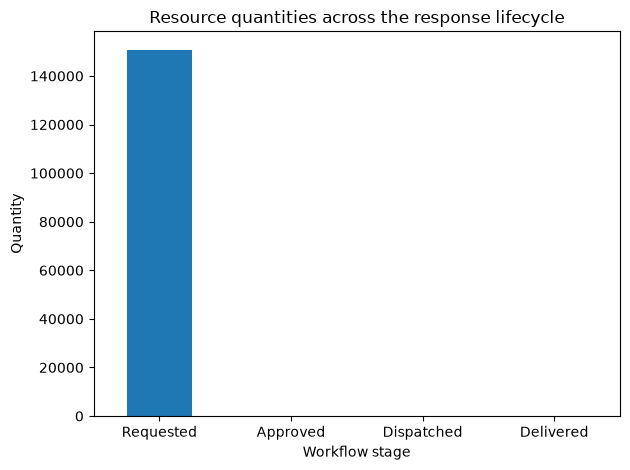


Audit verification: Workflow ledger verified
Dashboard generated. No records were modified.


In [123]:

import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Markdown

# Confirm that the previous workflow cells have been executed.
required_vars = ["state", "workflow_ledger", "verify_workflow_ledger"]

missing = [name for name in required_vars if name not in globals()]
if missing:
    raise RuntimeError(
        f"Run the previous workflow cells first. Missing: {missing}"
    )

# 1. Build the response overview.
items = state["allocations"]

df = pd.DataFrame([
    {
        "Allocation ID": allocation_id,
        "Scenario": item["scenario_id"],
        "Disaster": item["disaster_type"],
        "Zone": item["zone_id"],
        "Resource": item["resource_type"],
        "Priority": item["priority_score"],
        "Requested": item["requested_qty"],
        "Approved": item["approved_qty"],
        "Dispatched": item["dispatched_qty"],
        "Delivered": item["delivered_qty"],
        "Unmet Request": max(
            0, item["requested_qty"] - item["delivered_qty"]
        ),
        "Approval Status": item["approval_status"],
        "Data Status": item["data_status"],
    }
    for allocation_id, item in items.items()
])

if not df.empty:
    df = df.sort_values(
        ["Priority", "Zone"], ascending=[False, True]
    ).reset_index(drop=True)

valid, verification_message = verify_workflow_ledger(workflow_ledger)

display(Markdown("# HydroSeismic — Response Command Dashboard"))
display(Markdown(
    f"**Audit integrity:** {'VALID' if valid else 'INVALID'}  \n"
    f"**Workflow audit events:** {len(workflow_ledger['records'])}  \n"
    f"**Allocation cases:** {len(df)}"
))

# 2. Summary metrics.
pending = int((df["Approval Status"] == "PENDING").sum()) if not df.empty else 0
approved = int((df["Approval Status"] == "APPROVED").sum()) if not df.empty else 0
rejected = int((df["Approval Status"] == "REJECTED").sum()) if not df.empty else 0
dispatched_cases = sum(
    1 for item in items.values() if item["dispatched_qty"] > 0
)
delivered_cases = sum(
    1 for item in items.values()
    if item["delivered_qty"] >= item["dispatched_qty"]
    and item["dispatched_qty"] > 0
)

summary = pd.DataFrame([
    {"Metric": "Pending review", "Count": pending},
    {"Metric": "Approved", "Count": approved},
    {"Metric": "Rejected", "Count": rejected},
    {"Metric": "Cases dispatched", "Count": dispatched_cases},
    {"Metric": "Dispatches fully delivered", "Count": delivered_cases},
])

display(summary)

# 3. Highest-priority requests requiring action.
display(Markdown("## Highest-priority requests"))
if not df.empty:
    action_df = df[
        (df["Approval Status"] == "PENDING")
        | (df["Approved"] > df["Dispatched"])
        | (df["Dispatched"] > df["Delivered"])
    ]
    display(action_df.head(20))
else:
    display(Markdown("No allocation records are available."))

# 4. Inventory summary.
inventory_df = pd.DataFrame([
    {
        "Resource": resource,
        "Initial Stock": quantity,
        "Available Stock": state["inventory_available"].get(resource, 0),
        "Committed Stock": (
            quantity - state["inventory_available"].get(resource, 0)
        ),
    }
    for resource, quantity in state["inventory_initial"].items()
])

display(Markdown("## Inventory position"))
display(inventory_df)

# 5. Audit event history.
display(Markdown("## Recent audit events"))
events = workflow_ledger.get("records", [])

if events:
    event_df = pd.DataFrame([
        {
            "Event ID": event["event_id"],
            "Timestamp UTC": event["recorded_at_utc"],
            "Event Type": event["event_type"],
            "Previous Hash": event["previous_hash"][:12] + "...",
            "Record Hash": event["record_hash"][:12] + "...",
        }
        for event in events[-15:]
    ])
    display(event_df)
else:
    display(Markdown("No response workflow events have been recorded yet."))

# 6. Plot resource lifecycle totals.
if not df.empty:
    totals = df[["Requested", "Approved", "Dispatched", "Delivered"]].sum()

    ax = totals.plot(
        kind="bar",
        title="Resource quantities across the response lifecycle",
        xlabel="Workflow stage",
        ylabel="Quantity",
        rot=0
    )
    plt.tight_layout()
    plt.show()

print("\nAudit verification:", verification_message)
print("Dashboard generated. No records were modified.")


In [124]:

from datetime import datetime, timezone

REPORT_DIR = BASE / "reports"
REPORT_DIR.mkdir(parents=True, exist_ok=True)

timestamp = datetime.now(timezone.utc).strftime("%Y%m%dT%H%M%SZ")

allocation_report = REPORT_DIR / f"response_allocations_{timestamp}.csv"
inventory_report = REPORT_DIR / f"response_inventory_{timestamp}.csv"
audit_report = REPORT_DIR / f"response_audit_{timestamp}.json"

df.to_csv(allocation_report, index=False)
inventory_df.to_csv(inventory_report, index=False)

audit_snapshot = {
    "report_generated_at_utc": datetime.now(timezone.utc).isoformat(),
    "source": "HydroSeismic local response workflow prototype",
    "audit_integrity_valid": verify_workflow_ledger(workflow_ledger)[0],
    "event_count": len(workflow_ledger["records"]),
    "allocation_count": len(state["allocations"]),
    "allocation_data": df.to_dict(orient="records"),
    "inventory_data": inventory_df.to_dict(orient="records"),
    "notice": (
        "Prototype report. Demo reviewer identities and synthetic data "
        "are not evidence of real government approval or emergency dispatch."
    )
}

audit_report.write_text(
    json.dumps(audit_snapshot, indent=2, default=str),
    encoding="utf-8"
)

print("Reports created:")
print(allocation_report)
print(inventory_report)
print(audit_report)


Reports created:
/home/ibm-user/hydroseismic_data/reports/response_allocations_20261017T132346Z.csv
/home/ibm-user/hydroseismic_data/reports/response_inventory_20261017T132346Z.csv
/home/ibm-user/hydroseismic_data/reports/response_audit_20261017T132346Z.json


In [125]:

from pathlib import Path
import json
import hashlib
import copy
import tempfile
from datetime import datetime, timezone

PROJECT_DIR = Path("/home/ibm-user/hydroseismic_data")
PROJECT_DIR.mkdir(parents=True, exist_ok=True)

print("HydroSeismic project:", PROJECT_DIR)
print("Project directory exists:", PROJECT_DIR.exists())


HydroSeismic project: /home/ibm-user/hydroseismic_data
Project directory exists: True


In [127]:

class WorkflowError(Exception):
    pass


class ResponseWorkflow:
    def __init__(self, root, inventory=None):
        self.root = Path(root)
        self.root.mkdir(parents=True, exist_ok=True)

        self.ledger_path = self.root / "response_ledger.json"
        self.state_path = self.root / "response_state.json"

        if self.ledger_path.exists() or self.state_path.exists():
            if not self.ledger_path.exists() or not self.state_path.exists():
                raise WorkflowError("Incomplete ledger/state pair.")
            self.ledger = json.loads(self.ledger_path.read_text())
            self.state = json.loads(self.state_path.read_text())
            self.verify_chain()
        else:
            self.ledger = []
            self.state = {
                "inventory": inventory or {},
                "requests": {},
                "processed_commands": []
            }
            self._save()

    def _save(self):
        self.ledger_path.write_text(
            json.dumps(self.ledger, indent=2), encoding="utf-8"
        )
        self.state_path.write_text(
            json.dumps(self.state, indent=2), encoding="utf-8"
        )

    def verify_chain(self):
        previous = "GENESIS"

        for event in self.ledger:
            if event["previous_hash"] != previous:
                raise WorkflowError("Broken audit chain.")

            body = {k: v for k, v in event.items() if k != "hash"}
            expected = hashlib.sha256(
                json.dumps(
                    body, sort_keys=True, separators=(",", ":")
                ).encode()
            ).hexdigest()

            if event["hash"] != expected:
                raise WorkflowError("Audit hash mismatch.")

            previous = event["hash"]

        return True

    def _check_command(self, command_id):
        if not isinstance(command_id, str) or not command_id.strip():
            raise WorkflowError("A command ID is required.")

        if command_id in self.state["processed_commands"]:
            raise WorkflowError("Duplicate command rejected.")

    def _record(self, action, actor, request_id, details):
        previous = self.ledger[-1]["hash"] if self.ledger else "GENESIS"

        event = {
            "sequence": len(self.ledger) + 1,
            "timestamp": datetime.now(timezone.utc).isoformat(),
            "action": action,
            "actor": actor,
            "request_id": request_id,
            "details": details,
            "previous_hash": previous
        }

        event["hash"] = hashlib.sha256(
            json.dumps(
                event, sort_keys=True, separators=(",", ":")
            ).encode()
        ).hexdigest()

        self.ledger.append(event)

    def _commit(self, command_id, action, actor, request_id, details):
        self.state["processed_commands"].append(command_id)
        self._record(action, actor, request_id, details)
        self._save()

    def submit(self, request_id, zone, items, actor, command_id):
        self._check_command(command_id)

        if not request_id or request_id in self.state["requests"]:
            raise WorkflowError("Invalid or duplicate request ID.")

        if not zone or not items:
            raise WorkflowError("Zone and items are required.")

        clean_items = {}

        for item, quantity in items.items():
            if (not isinstance(quantity, int)
                    or isinstance(quantity, bool) or quantity <= 0):
                raise WorkflowError(f"Invalid quantity: {item}")
            clean_items[item] = quantity

        self.state["requests"][request_id] = {
            "zone": zone,
            "items": clean_items,
            "status": "PENDING",
            "reserved": {},
            "delivered": {},
            "approved_by": None
        }

        self._commit(
            command_id, "REQUEST_SUBMITTED", actor, request_id,
            {"zone": zone, "items": clean_items}
        )

    def review(self, request_id, decision, actor, role, command_id):
        self._check_command(command_id)

        if role != "government_approver":
            raise WorkflowError("Government approver permission required.")

        if decision not in ("APPROVE", "REJECT"):
            raise WorkflowError("Decision must be APPROVE or REJECT.")

        request = self._request(request_id)

        if request["status"] != "PENDING":
            raise WorkflowError("Request is not pending.")

        request["status"] = (
            "APPROVED" if decision == "APPROVE" else "REJECTED"
        )
        request["approved_by"] = actor

        self._commit(
            command_id, "REQUEST_" + decision, actor, request_id,
            {"zone": request["zone"], "role": role}
        )

    def reserve(self, request_id, actor, command_id):
        self._check_command(command_id)
        request = self._request(request_id)

        if request["status"] != "APPROVED":
            raise WorkflowError("Approval is required before reservation.")

        inventory = self.state["inventory"]

        for item, quantity in request["items"].items():
            available = inventory.get(item, 0)
            if (not isinstance(available, int)
                    or isinstance(available, bool)
                    or available < quantity):
                raise WorkflowError(f"Insufficient stock: {item}")

        for item, quantity in request["items"].items():
            inventory[item] -= quantity

        request["reserved"] = copy.deepcopy(request["items"])
        request["status"] = "RESERVED"

        self._commit(
            command_id, "RESOURCES_RESERVED", actor, request_id,
            {"items": request["reserved"]}
        )

    def dispatch(self, request_id, actor, command_id):
        self._check_command(command_id)
        request = self._request(request_id)

        if request["status"] != "RESERVED":
            raise WorkflowError("Resources must be reserved first.")

        request["status"] = "DISPATCHED"

        self._commit(
            command_id, "RESOURCES_DISPATCHED", actor, request_id,
            {"items": request["reserved"]}
        )

    def confirm_delivery(self, request_id, delivered, actor, command_id):
        self._check_command(command_id)
        request = self._request(request_id)

        if request["status"] != "DISPATCHED":
            raise WorkflowError("Resources must be dispatched first.")

        if delivered != request["reserved"]:
            raise WorkflowError("Delivery does not match reserved quantities.")

        request["delivered"] = copy.deepcopy(delivered)
        request["status"] = "DELIVERED"

        self._commit(
            command_id, "DELIVERY_CONFIRMED", actor, request_id,
            {"zone": request["zone"], "items": delivered}
        )

    def _request(self, request_id):
        if request_id not in self.state["requests"]:
            raise WorkflowError("Unknown request ID.")
        return self.state["requests"][request_id]


In [128]:

with tempfile.TemporaryDirectory() as temp_dir:
    app = ResponseWorkflow(
        temp_dir,
        inventory={
            "WATER": 500,
            "FOOD": 200,
            "MEDICAL_KITS": 30
        }
    )

    app.submit(
        "REQ-001", "ZONE-A",
        {"WATER": 100, "FOOD": 40, "MEDICAL_KITS": 5},
        "zone_officer", "CMD-001"
    )

    try:
        app.review(
            "REQ-001", "APPROVE", "unauthorized_user",
            "citizen", "CMD-002"
        )
        raise AssertionError("Unauthorized approval was accepted")
    except WorkflowError as error:
        print("PASS: unauthorized approval blocked")

    app.review(
        "REQ-001", "APPROVE", "gov_officer_01",
        "government_approver", "CMD-003"
    )

    app.reserve("REQ-001", "inventory_officer", "CMD-004")
    app.dispatch("REQ-001", "dispatch_officer", "CMD-005")

    app.confirm_delivery(
        "REQ-001",
        {"WATER": 100, "FOOD": 40, "MEDICAL_KITS": 5},
        "delivery_officer", "CMD-006"
    )

    assert app.state["requests"]["REQ-001"]["status"] == "DELIVERED"
    assert app.state["inventory"] == {
        "WATER": 400,
        "FOOD": 160,
        "MEDICAL_KITS": 25
    }

    print("PASS: request approved")
    print("PASS: inventory reserved")
    print("PASS: dispatch completed")
    print("PASS: delivery confirmed")
    print("PASS: inventory updated correctly")
    print("PASS: audit chain valid:", app.verify_chain())
    print("Audit events:", len(app.ledger))


PASS: unauthorized approval blocked
PASS: request approved
PASS: inventory reserved
PASS: dispatch completed
PASS: delivery confirmed
PASS: inventory updated correctly
PASS: audit chain valid: True
Audit events: 5


In [129]:

with tempfile.TemporaryDirectory() as temp_dir:
    app = ResponseWorkflow(temp_dir, {"WATER": 100})

    app.submit("REQ-002", "ZONE-B", {"WATER": 20},
               "zone_officer", "CMD-A")

    app.review("REQ-002", "APPROVE", "gov_officer_01",
               "government_approver", "CMD-B")

    app.reserve("REQ-002", "inventory_officer", "CMD-C")

    try:
        app.reserve("REQ-002", "inventory_officer", "CMD-D")
        raise AssertionError("Duplicate reservation was accepted")
    except WorkflowError as error:
        print("PASS:", error)

    print("Remaining water:", app.state["inventory"]["WATER"])
    print("Expected remaining water: 80")


PASS: Approval is required before reservation.
Remaining water: 80
Expected remaining water: 80


In [130]:

print("HYDROSEISMIC WORKFLOW TEST SUMMARY")
print("=" * 40)

checks = {
    "Workflow class created": "ResponseWorkflow" in globals(),
    "Custom error class created": "WorkflowError" in globals(),
    "Audit verification available": hasattr(ResponseWorkflow, "verify_chain"),
    "Approval workflow available": hasattr(ResponseWorkflow, "review"),
    "Inventory reservation available": hasattr(ResponseWorkflow, "reserve"),
    "Dispatch available": hasattr(ResponseWorkflow, "dispatch"),
    "Delivery confirmation available": hasattr(ResponseWorkflow, "confirm_delivery")
}

for name, passed in checks.items():
    print(f"[{'PASS' if passed else 'FAIL'}] {name}")

print("\nNext milestone: integrate this engine with the existing")
print("HydroSeismic API, risk assessment, and website dashboard.")


HYDROSEISMIC WORKFLOW TEST SUMMARY
[PASS] Workflow class created
[PASS] Custom error class created
[PASS] Audit verification available
[PASS] Approval workflow available
[PASS] Inventory reservation available
[PASS] Dispatch available
[PASS] Delivery confirmation available

Next milestone: integrate this engine with the existing
HydroSeismic API, risk assessment, and website dashboard.


In [133]:

import importlib.util
import sys

print("Python:", sys.version)

for package in ["fastapi", "uvicorn", "pydantic", "httpx"]:
    available = importlib.util.find_spec(package) is not None
    print(f"{package}: {'INSTALLED' if available else 'MISSING'}")

%pip install fastapi uvicorn pydantic httpx

import fastapi
import uvicorn
import pydantic
import httpx

print("FastAPI:", fastapi.__version__)
print("Uvicorn:", uvicorn.__version__)
print("Pydantic:", pydantic.__version__)
print("HTTPX:", httpx.__version__)
print("All required packages imported successfully.")


Python: 3.12.15 (main, Oct  1 2026, 00:00:00) [GCC 14.3.1 20251022 (Red Hat 14.3.1-4)]
fastapi: MISSING
uvicorn: MISSING
pydantic: MISSING
httpx: INSTALLED
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2.4/2.4 MB 15.1 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 8/8 [fastapi]m7/8 [fastapi]]core]
Note: you may need to restart the kernel to use updated packages.
FastAPI: 0.143.3
Uvicorn: 0.54.0
Pydantic: 2.14.1
HTTPX: 0.28.1
All required packages imported successfully.


In [134]:

from pathlib import Path
from fastapi import FastAPI, HTTPException
from pydantic import BaseModel, Field

API_DATA_DIR = Path(
    "/home/ibm-user/hydroseismic_data/api_prototype"
)
API_DATA_DIR.mkdir(parents=True, exist_ok=True)

# Separate persistent prototype state.
workflow = ResponseWorkflow(
    API_DATA_DIR,
    inventory={
        "WATER": 50000,
        "FOOD": 20000,
        "MEDICAL_KITS": 3000,
        "AMBULANCE": 8,
        "RESCUE_TEAM": 4
    }
)

app = FastAPI(
    title="HydroSeismic Emergency Response API",
    version="0.1.0",
    description="Prototype relief request and dispatch workflow"
)


class ReliefRequest(BaseModel):
    request_id: str
    zone: str
    items: dict[str, int]
    actor: str
    command_id: str


class ReviewRequest(BaseModel):
    decision: str
    actor: str
    role: str
    command_id: str


class ActionRequest(BaseModel):
    actor: str
    command_id: str


class DeliveryRequest(ActionRequest):
    delivered: dict[str, int]


def execute(operation):
    try:
        return operation()
    except WorkflowError as exc:
        raise HTTPException(status_code=400, detail=str(exc))


@app.get("/")
def root():
    return {
        "project": "HydroSeismic",
        "api_status": "running",
        "docs": "/docs"
    }


@app.get("/health")
def health():
    return {
        "status": "healthy",
        "audit_chain_valid": execute(workflow.verify_chain)
    }


@app.get("/inventory")
def get_inventory():
    return workflow.state["inventory"]


@app.get("/requests")
def get_requests():
    return workflow.state["requests"]


@app.get("/audit")
def get_audit():
    return {
        "count": len(workflow.ledger),
        "chain_valid": execute(workflow.verify_chain),
        "events": workflow.ledger
    }


@app.post("/requests")
def create_request(data: ReliefRequest):
    execute(lambda: workflow.submit(
        data.request_id,
        data.zone,
        data.items,
        data.actor,
        data.command_id
    ))
    return {"status": "PENDING", "request_id": data.request_id}


@app.post("/requests/{request_id}/review")
def review_request(request_id: str, data: ReviewRequest):
    execute(lambda: workflow.review(
        request_id,
        data.decision,
        data.actor,
        data.role,
        data.command_id
    ))
    return {
        "request_id": request_id,
        "status": workflow.state["requests"][request_id]["status"]
    }


@app.post("/requests/{request_id}/reserve")
def reserve_resources(request_id: str, data: ActionRequest):
    execute(lambda: workflow.reserve(
        request_id, data.actor, data.command_id
    ))
    return {"request_id": request_id, "status": "RESERVED"}


@app.post("/requests/{request_id}/dispatch")
def dispatch_resources(request_id: str, data: ActionRequest):
    execute(lambda: workflow.dispatch(
        request_id, data.actor, data.command_id
    ))
    return {"request_id": request_id, "status": "DISPATCHED"}


@app.post("/requests/{request_id}/delivery")
def confirm_delivery(request_id: str, data: DeliveryRequest):
    execute(lambda: workflow.confirm_delivery(
        request_id,
        data.delivered,
        data.actor,
        data.command_id
    ))
    return {"request_id": request_id, "status": "DELIVERED"}


print("HydroSeismic API defined.")
print("Endpoints:", len(app.routes))


HydroSeismic API defined.
Endpoints: 14


In [135]:

import uvicorn
import threading
import time
import urllib.request

def start_api():
    uvicorn.run(app, host="127.0.0.1", port=8000, log_level="info")

api_thread = threading.Thread(target=start_api, daemon=True)
api_thread.start()

time.sleep(2)

try:
    with urllib.request.urlopen(
        "http://127.0.0.1:8000/health", timeout=5
    ) as response:
        print("HTTP status:", response.status)
        print(response.read().decode())
except Exception as error:
    print("API startup/check error:", error)


INFO:     Started server process [1433]
INFO:     Waiting for application startup.
INFO:     Application startup complete.
INFO:     Uvicorn running on http://127.0.0.1:8000 (Press CTRL+C to quit)


INFO:     127.0.0.1:53982 - "GET /health HTTP/1.1" 200 OK
HTTP status: 200
{"status":"healthy","audit_chain_valid":true}


In [136]:

import httpx
import uuid

BASE_URL = "http://127.0.0.1:8000"
test_id = uuid.uuid4().hex[:10].upper()
request_id = f"TEST-{test_id}"

def check(response, expected_status=200):
    print("HTTP", response.status_code, response.request.method,
          response.request.url.path)
    if response.status_code != expected_status:
        print(response.text)
        response.raise_for_status()
    return response.json()

with httpx.Client(base_url=BASE_URL, timeout=15) as client:

    # 1. Submit a relief request
    result = check(client.post("/requests", json={
        "request_id": request_id,
        "zone": "TEST-ZONE-A",
        "items": {"WATER": 10, "FOOD": 5},
        "actor": "test_zone_officer",
        "command_id": f"{test_id}-SUBMIT"
    }))
    assert result["status"] == "PENDING"
    print("PASS: relief request created")

    # 2. Government-authorized prototype approval
    result = check(client.post(
        f"/requests/{request_id}/review",
        json={
            "decision": "APPROVE",
            "actor": "test_government_approver",
            "role": "government_approver",
            "command_id": f"{test_id}-REVIEW"
        }
    ))
    assert result["status"] == "APPROVED"
    print("PASS: request approved")

    # 3. Reserve the resources
    result = check(client.post(
        f"/requests/{request_id}/reserve",
        json={
            "actor": "test_inventory_officer",
            "command_id": f"{test_id}-RESERVE"
        }
    ))
    assert result["status"] == "RESERVED"
    print("PASS: inventory reserved")

    # 4. Dispatch the resources
    result = check(client.post(
        f"/requests/{request_id}/dispatch",
        json={
            "actor": "test_dispatch_officer",
            "command_id": f"{test_id}-DISPATCH"
        }
    ))
    assert result["status"] == "DISPATCHED"
    print("PASS: resources dispatched")

    # 5. Confirm delivery
    result = check(client.post(
        f"/requests/{request_id}/delivery",
        json={
            "actor": "test_delivery_officer",
            "command_id": f"{test_id}-DELIVERY",
            "delivered": {"WATER": 10, "FOOD": 5}
        }
    ))
    assert result["status"] == "DELIVERED"
    print("PASS: delivery confirmed")

    # 6. Verify final state and audit
    requests_data = check(client.get("/requests"))
    inventory = check(client.get("/inventory"))
    audit = check(client.get("/audit"))

    assert requests_data[request_id]["status"] == "DELIVERED"
    assert audit["chain_valid"] is True

    print("\n===== END-TO-END RESULT =====")
    print("Request:", request_id)
    print("Final status:", requests_data[request_id]["status"])
    print("Remaining WATER:", inventory["WATER"])
    print("Remaining FOOD:", inventory["FOOD"])
    print("Audit events:", audit["count"])
    print("Audit chain valid:", audit["chain_valid"])
    print("PASS: complete API workflow")


INFO:     127.0.0.1:58678 - "POST /requests HTTP/1.1" 200 OK
HTTP 200 POST /requests
PASS: relief request created
INFO:     127.0.0.1:58678 - "POST /requests/TEST-2FE86DB70E/review HTTP/1.1" 200 OK
HTTP 200 POST /requests/TEST-2FE86DB70E/review
PASS: request approved
INFO:     127.0.0.1:58678 - "POST /requests/TEST-2FE86DB70E/reserve HTTP/1.1" 200 OK
HTTP 200 POST /requests/TEST-2FE86DB70E/reserve
PASS: inventory reserved
INFO:     127.0.0.1:58678 - "POST /requests/TEST-2FE86DB70E/dispatch HTTP/1.1" 200 OK
HTTP 200 POST /requests/TEST-2FE86DB70E/dispatch
PASS: resources dispatched
INFO:     127.0.0.1:58678 - "POST /requests/TEST-2FE86DB70E/delivery HTTP/1.1" 200 OK
HTTP 200 POST /requests/TEST-2FE86DB70E/delivery
PASS: delivery confirmed
INFO:     127.0.0.1:58678 - "GET /requests HTTP/1.1" 200 OK
HTTP 200 GET /requests
INFO:     127.0.0.1:58678 - "GET /inventory HTTP/1.1" 200 OK
HTTP 200 GET /inventory
INFO:     127.0.0.1:58678 - "GET /audit HTTP/1.1" 200 OK
HTTP 200 GET /audit

===== 

In [137]:

import csv
from pathlib import Path
from collections import defaultdict

BASE = Path("/home/ibm-user/hydroseismic_data")
ALLOCATION_FILE = BASE / "processed" / "allocation_recommendations.csv"

if not ALLOCATION_FILE.exists():
    raise FileNotFoundError(
        f"Allocation recommendations not found: {ALLOCATION_FILE}"
    )

with ALLOCATION_FILE.open(newline="", encoding="utf-8") as f:
    allocation_rows = list(csv.DictReader(f))

if not allocation_rows:
    raise ValueError("Allocation file contains no records.")

print("Loaded allocation recommendations:", len(allocation_rows))
print("Available fields:")
print(list(allocation_rows[0].keys()))

print("\nSample records:")
for row in allocation_rows[:5]:
    print({
        key: row.get(key)
        for key in [
            "scenario_id", "disaster_type", "request_id",
            "zone_id", "resource_type", "requested_qty",
            "allocated_qty", "unmet_qty", "priority_score",
            "allocation_status", "data_status"
        ]
        if key in row
    })


Loaded allocation recommendations: 13
Available fields:
['request_id', 'scenario_id', 'disaster_type', 'zone_id', 'resource_type', 'requested_qty', 'urgency', 'exposure', 'criticality', 'priority_score', 'available_before_allocation', 'allocated_qty', 'unmet_qty', 'remaining_inventory', 'allocation_status', 'approval_status', 'data_status']

Sample records:
{'scenario_id': 'SIM-EQ-001', 'disaster_type': 'EARTHQUAKE', 'request_id': 'REQ-EQ-004', 'zone_id': 'DEMO-ZONE-C', 'resource_type': 'RESCUE_TEAM', 'requested_qty': '6', 'allocated_qty': '4', 'unmet_qty': '2', 'priority_score': '97.5', 'allocation_status': 'PARTIAL', 'data_status': 'SYNTHETIC_DEMO'}
{'scenario_id': 'SIM-EQ-001', 'disaster_type': 'EARTHQUAKE', 'request_id': 'REQ-EQ-001', 'zone_id': 'DEMO-HOSPITAL-ZONE', 'resource_type': 'MEDICAL_KITS', 'requested_qty': '3500', 'allocated_qty': '3000', 'unmet_qty': '500', 'priority_score': '97.0', 'allocation_status': 'PARTIAL', 'data_status': 'SYNTHETIC_DEMO'}
{'scenario_id': 'SIM-EQ-

In [138]:

zone_summary = defaultdict(lambda: {
    "disaster_types": set(),
    "scenarios": set(),
    "resources": set(),
    "max_priority": None,
    "unmet_total": 0,
    "records": 0,
    "data_statuses": set()
})

def parse_number(value):
    try:
        return float(value)
    except (TypeError, ValueError):
        return None

for row in allocation_rows:
    zone = row.get("zone_id", "").strip() or "UNKNOWN_ZONE"
    summary = zone_summary[zone]

    summary["records"] += 1

    if row.get("disaster_type"):
        summary["disaster_types"].add(row["disaster_type"])

    if row.get("scenario_id"):
        summary["scenarios"].add(row["scenario_id"])

    if row.get("resource_type"):
        summary["resources"].add(row["resource_type"])

    if row.get("data_status"):
        summary["data_statuses"].add(row["data_status"])

    priority = parse_number(row.get("priority_score"))
    if priority is not None:
        current = summary["max_priority"]
        summary["max_priority"] = (
            priority if current is None else max(current, priority)
        )

    unmet = parse_number(row.get("unmet_qty"))
    if unmet is not None and unmet >= 0:
        summary["unmet_total"] += unmet

ranked_zones = sorted(
    zone_summary.items(),
    key=lambda item: (
        item[1]["max_priority"] is not None,
        item[1]["max_priority"] if item[1]["max_priority"] is not None else -1
    ),
    reverse=True
)

print("HYDROSEISMIC — ZONE PRIORITY REVIEW")
print("=" * 70)

for rank, (zone, s) in enumerate(ranked_zones, start=1):
    print(f"\nRank: {rank} | Zone: {zone}")
    print("Disasters:", ", ".join(sorted(s["disaster_types"]) or ["Unknown"]))
    print("Scenarios:", ", ".join(sorted(s["scenarios"]) or ["Unknown"]))
    print("Highest recorded priority:", s["max_priority"])
    print("Recorded unmet quantity total:", s["unmet_total"])
    print("Resource types:", ", ".join(sorted(s["resources"]) or ["Unknown"]))
    print("Data status:", ", ".join(sorted(s["data_statuses"]) or ["Unknown"]))
    print("Recommendation records:", s["records"])

print("\nNOTE: This is a ranking of existing recommendations,")
print("not a new predictive model or a verified live emergency ranking.")


HYDROSEISMIC — ZONE PRIORITY REVIEW

Rank: 1 | Zone: DEMO-ZONE-C
Disasters: EARTHQUAKE
Scenarios: SIM-EQ-001
Highest recorded priority: 97.5
Recorded unmet quantity total: 2.0
Resource types: RESCUE_TEAM, WATER
Data status: SYNTHETIC_DEMO
Recommendation records: 2

Rank: 2 | Zone: DEMO-HOSPITAL-ZONE
Disasters: EARTHQUAKE, FLOOD
Scenarios: SIM-EQ-001, SIM-FLOOD-001, SIM-FLOOD-002
Highest recorded priority: 97.0
Recorded unmet quantity total: 504.0
Resource types: AMBULANCE, MEDICAL_KITS
Data status: SYNTHETIC_DEMO
Recommendation records: 6

Rank: 3 | Zone: DEMO-ZONE-A
Disasters: FLOOD
Scenarios: SIM-FLOOD-001, SIM-FLOOD-002
Highest recorded priority: 95.5
Recorded unmet quantity total: 20000.0
Resource types: FOOD, WATER
Data status: SYNTHETIC_DEMO
Recommendation records: 4

Rank: 4 | Zone: DEMO-ZONE-B
Disasters: FLOOD
Scenarios: SIM-FLOOD-002
Highest recorded priority: 92.5
Recorded unmet quantity total: 2.0
Resource types: RESCUE_TEAM
Data status: SYNTHETIC_DEMO
Recommendation records

In [139]:

review_items = []

for row in allocation_rows:
    requested = parse_number(row.get("requested_qty"))
    allocated = parse_number(row.get("allocated_qty"))
    unmet = parse_number(row.get("unmet_qty"))

    problems = []

    if not row.get("zone_id"):
        problems.append("Missing zone ID")

    if not row.get("resource_type"):
        problems.append("Missing resource type")

    if allocated is None or allocated < 0 or not allocated.is_integer():
        problems.append("Invalid allocated quantity")

    if requested is None or requested < 0:
        problems.append("Invalid requested quantity")

    if unmet is None or unmet < 0:
        problems.append("Invalid unmet quantity")

    if row.get("data_status", "").upper() in {
        "SYNTHETIC_DEMO", "SIMULATED", "SYNTHETIC"
    }:
        problems.append("Demonstration data — not a real incident")

    review_items.append({
        "request_id": row.get("request_id", ""),
        "zone_id": row.get("zone_id", ""),
        "resource_type": row.get("resource_type", ""),
        "allocated_qty": allocated,
        "approval_status": "PENDING_HUMAN_REVIEW",
        "issues": problems
    })

for item in review_items[:20]:
    print(item)

print("\nTotal recommendations reviewed:", len(review_items))
print("No relief shipments were created by this cell.")


{'request_id': 'REQ-EQ-004', 'zone_id': 'DEMO-ZONE-C', 'resource_type': 'RESCUE_TEAM', 'allocated_qty': 4.0, 'approval_status': 'PENDING_HUMAN_REVIEW', 'issues': ['Demonstration data — not a real incident']}
{'request_id': 'REQ-EQ-001', 'zone_id': 'DEMO-HOSPITAL-ZONE', 'resource_type': 'MEDICAL_KITS', 'allocated_qty': 3000.0, 'approval_status': 'PENDING_HUMAN_REVIEW', 'issues': ['Demonstration data — not a real incident']}
{'request_id': 'REQ-EQ-002', 'zone_id': 'DEMO-HOSPITAL-ZONE', 'resource_type': 'AMBULANCE', 'allocated_qty': 8.0, 'approval_status': 'PENDING_HUMAN_REVIEW', 'issues': ['Demonstration data — not a real incident']}
{'request_id': 'REQ-EQ-003', 'zone_id': 'DEMO-ZONE-C', 'resource_type': 'WATER', 'allocated_qty': 30000.0, 'approval_status': 'PENDING_HUMAN_REVIEW', 'issues': ['Demonstration data — not a real incident']}
{'request_id': 'REQ-FB-001', 'zone_id': 'DEMO-ZONE-A', 'resource_type': 'WATER', 'allocated_qty': 18000.0, 'approval_status': 'PENDING_HUMAN_REVIEW', 'iss

In [140]:

import csv
import json
import uuid
from pathlib import Path
from datetime import datetime, timezone

BASE = Path("/home/ibm-user/hydroseismic_data")
INPUT = BASE / "processed" / "allocation_recommendations.csv"
OUTPUT_DIR = BASE / "processed"
OUTPUT = OUTPUT_DIR / "response_review_queue.json"

if not INPUT.exists():
    raise FileNotFoundError(f"Missing input file: {INPUT}")

with INPUT.open(newline="", encoding="utf-8") as f:
    rows = list(csv.DictReader(f))

if not rows:
    raise ValueError("Allocation recommendations are empty.")

required = {
    "zone_id", "resource_type", "requested_qty",
    "allocated_qty", "unmet_qty", "data_status"
}
missing = required - set(rows[0].keys())

if missing:
    raise ValueError(f"Missing required columns: {sorted(missing)}")


def quantity(value, field):
    try:
        number = float(value)
    except (TypeError, ValueError):
        raise ValueError(f"Invalid {field}: {value!r}") from None

    if not number.is_integer() or number < 0:
        raise ValueError(f"{field} must be a non-negative integer.")

    return int(number)


review_queue = []

for index, row in enumerate(rows, start=1):
    requested = quantity(row["requested_qty"], "requested_qty")
    allocated = quantity(row["allocated_qty"], "allocated_qty")
    unmet = quantity(row["unmet_qty"], "unmet_qty")

    issues = []

    if not row["zone_id"].strip():
        issues.append("Missing zone ID")

    if not row["resource_type"].strip():
        issues.append("Missing resource type")

    if allocated + unmet != requested:
        issues.append("Requested, allocated and unmet quantities do not reconcile")

    data_status = row["data_status"].strip().upper()
    if data_status in {"SYNTHETIC_DEMO", "SIMULATED", "SYNTHETIC"}:
        issues.append("Synthetic scenario; demo review only")

    priority_raw = row.get("priority_score", "")
    try:
        priority = float(priority_raw) if priority_raw.strip() else None
    except ValueError:
        priority = None
        issues.append("Invalid priority score")

    review_queue.append({
        "review_id": f"HS-REVIEW-{index:05d}",
        "scenario_id": row.get("scenario_id", ""),
        "disaster_type": row.get("disaster_type", ""),
        "source_request_id": row.get("request_id", ""),
        "zone_id": row["zone_id"].strip(),
        "resource_type": row["resource_type"].strip().upper(),
        "requested_qty": requested,
        "recommended_qty": allocated,
        "unmet_qty": unmet,
        "priority_score": priority,
        "data_status": data_status or "UNKNOWN",
        "review_status": "PENDING_HUMAN_REVIEW",
        "issues": issues
    })

OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

document = {
    "project": "HydroSeismic",
    "created_at_utc": datetime.now(timezone.utc).isoformat(),
    "source": str(INPUT),
    "record_count": len(review_queue),
    "notice": (
        "Review queue only. No approval, inventory reservation, "
        "dispatch, or delivery is performed."
    ),
    "records": review_queue
}

OUTPUT.write_text(json.dumps(document, indent=2), encoding="utf-8")

print("Recommendations processed:", len(review_queue))
print("Review queue saved to:", OUTPUT)
print("No existing source records were modified.")


Recommendations processed: 13
Review queue saved to: /home/ibm-user/hydroseismic_data/processed/response_review_queue.json
No existing source records were modified.


In [141]:

from collections import Counter

status_counts = Counter()
issue_counts = Counter()

for item in review_queue:
    status_counts[item["review_status"]] += 1

    for issue in item["issues"]:
        issue_counts[issue] += 1

print("HYDROSEISMIC REVIEW QUEUE")
print("=" * 45)
print("Total recommendations:", len(review_queue))
print("Review statuses:", dict(status_counts))
print("\nValidation findings:")

if issue_counts:
    for issue, count in issue_counts.items():
        print(f"- {issue}: {count}")
else:
    print("No validation issues found.")

print("\nHighest-priority recommendations:")
ranked = sorted(
    review_queue,
    key=lambda x: (
        x["priority_score"] is not None,
        x["priority_score"] if x["priority_score"] is not None else -1
    ),
    reverse=True
)

for item in ranked[:10]:
    print(
        item["zone_id"],
        "|", item["resource_type"],
        "| recommended:", item["recommended_qty"],
        "| priority:", item["priority_score"],
        "| review:", item["review_status"],
        "| issues:", item["issues"]
    )


HYDROSEISMIC REVIEW QUEUE
Total recommendations: 13
Review statuses: {'PENDING_HUMAN_REVIEW': 13}

Validation findings:
- Synthetic scenario; demo review only: 13

Highest-priority recommendations:
DEMO-ZONE-C | RESCUE_TEAM | recommended: 4 | priority: 97.5 | review: PENDING_HUMAN_REVIEW | issues: ['Synthetic scenario; demo review only']
DEMO-HOSPITAL-ZONE | MEDICAL_KITS | recommended: 3000 | priority: 97.0 | review: PENDING_HUMAN_REVIEW | issues: ['Synthetic scenario; demo review only']
DEMO-HOSPITAL-ZONE | AMBULANCE | recommended: 8 | priority: 97.0 | review: PENDING_HUMAN_REVIEW | issues: ['Synthetic scenario; demo review only']
DEMO-ZONE-A | WATER | recommended: 50000 | priority: 95.5 | review: PENDING_HUMAN_REVIEW | issues: ['Synthetic scenario; demo review only']
DEMO-ZONE-B | RESCUE_TEAM | recommended: 4 | priority: 92.5 | review: PENDING_HUMAN_REVIEW | issues: ['Synthetic scenario; demo review only']
DEMO-ZONE-A | FOOD | recommended: 20000 | priority: 91.0 | review: PENDING_HUM

In [142]:

import httpx

API_URL = "http://127.0.0.1:8000"

try:
    response = httpx.get(f"{API_URL}/health", timeout=5)
    print("HTTP status:", response.status_code)
    print("Response:", response.json())
    response.raise_for_status()
except Exception as error:
    print("API unavailable:", error)
    print("Restart the API server before integration testing.")


INFO:     127.0.0.1:52708 - "GET /health HTTP/1.1" 200 OK
HTTP status: 200
Response: {'status': 'healthy', 'audit_chain_valid': True}


In [143]:

import json
from pathlib import Path
from collections import Counter

PROJECT_DIR = Path("/home/ibm-user/hydroseismic_data")
QUEUE_PATH = PROJECT_DIR / "processed" / "response_review_queue.json"

if not QUEUE_PATH.exists():
    raise FileNotFoundError(
        f"{QUEUE_PATH} not found. Run Cell 14 first."
    )

with QUEUE_PATH.open("r", encoding="utf-8") as f:
    review_queue = json.load(f)

# Accept either a list or a dictionary containing the review items.
if isinstance(review_queue, dict):
    review_items = review_queue.get(
        "items",
        review_queue.get("recommendations", [])
    )
else:
    review_items = review_queue

if not isinstance(review_items, list):
    raise ValueError("Unexpected review-queue format.")

print("HYDROSEISMIC — RECOMMENDATION REVIEW QUEUE")
print("=" * 55)
print("Items loaded:", len(review_items))

if review_items:
    print("\nFirst item fields:")
    print(sorted(review_items[0].keys()))

    print("\nReview-status counts:")
    print(dict(Counter(
        str(item.get("review_status", "UNKNOWN"))
        for item in review_items
    )))

    print("\nData-status counts:")
    print(dict(Counter(
        str(item.get("data_status", "UNKNOWN"))
        for item in review_items
    )))

    print("\nSample recommendations:")
    for item in review_items[:5]:
        print({
            "scenario_id": item.get("scenario_id"),
            "source_request_id": item.get("request_id"),
            "zone_id": item.get("zone_id"),
            "resource_type": item.get("resource_type"),
            "allocated_qty": item.get("allocated_qty"),
            "data_status": item.get("data_status"),
            "review_status": item.get("review_status"),
        })
else:
    print("The review queue is empty. Run Cell 14 again and inspect its validation output.")


HYDROSEISMIC — RECOMMENDATION REVIEW QUEUE
Items loaded: 0
The review queue is empty. Run Cell 14 again and inspect its validation output.


In [144]:

from fastapi import HTTPException
from collections import Counter
import json

def load_review_queue():
    if not QUEUE_PATH.exists():
        raise HTTPException(
            status_code=404,
            detail="Review queue not found. Run Cell 14 first."
        )

    with QUEUE_PATH.open("r", encoding="utf-8") as f:
        data = json.load(f)

    if isinstance(data, dict):
        items = data.get("items", data.get("recommendations", []))
    else:
        items = data

    if not isinstance(items, list):
        raise HTTPException(
            status_code=500,
            detail="Invalid recommendation queue format."
        )

    return items


@app.get("/recommendations")
def get_recommendations(
    review_status: str = None,
    zone_id: str = None
):
    """Read recommendations for human review; does not dispatch resources."""
    items = load_review_queue()

    if review_status:
        items = [
            item for item in items
            if str(item.get("review_status", "")).upper()
            == review_status.upper()
        ]

    if zone_id:
        items = [
            item for item in items
            if str(item.get("zone_id", "")).casefold()
            == zone_id.casefold()
        ]

    return {
        "count": len(items),
        "mode": "REVIEW_ONLY",
        "items": items
    }


@app.get("/recommendations/summary")
def recommendation_summary():
    items = load_review_queue()

    return {
        "total": len(items),
        "review_status_counts": dict(Counter(
            str(item.get("review_status", "UNKNOWN"))
            for item in items
        )),
        "data_status_counts": dict(Counter(
            str(item.get("data_status", "UNKNOWN"))
            for item in items
        )),
        "warning": (
            "Recommendations require human validation. "
            "Synthetic demo data is not evidence of a real disaster."
        )
    }


print("Recommendation API routes registered.")
print("GET /recommendations")
print("GET /recommendations/summary")


Recommendation API routes registered.
GET /recommendations
GET /recommendations/summary


In [145]:

from IPython.display import display, Markdown

display(Markdown(
    "**HydroSeismic API documentation:** "
    "[Open Swagger UI](http://127.0.0.1:8000/docs)"
))


**HydroSeismic API documentation:** [Open Swagger UI](http://127.0.0.1:8000/docs)